In [2]:
# ==========================================================
# Inventory Management
# BLOCK 1 - Environment Setup
# ==========================================================

!pip -q install xgboost shap openpyxl

import os
import glob
import zipfile
import random
import warnings
import time
import joblib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# ----------------------------------------------------------
# Machine Learning
# ----------------------------------------------------------

from sklearn.model_selection import TimeSeriesSplit

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)

from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier


# ----------------------------------------------------------
# Settings
# ----------------------------------------------------------

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)


# ==========================================================
# PROJECT INFORMATION
# ==========================================================

print("=" * 70)
print("Inventory Management")
print("Environment Setup")
print("=" * 70)

print(
    "Project: ML-Based Fashion Inventory Waste Risk Prediction"
)

print(
    f"Random State : {RANDOM_STATE}"
)

print(
    f"NumPy        : {np.__version__}"
)

print(
    f"Pandas       : {pd.__version__}"
)


# ==========================================================
# UPLOAD DATASET
# ==========================================================

print("\n" + "=" * 70)

print(
    "Upload the Retail Store Inventory / Sales ZIP file."
)

print("=" * 70)

uploaded = files.upload()


# ==========================================================
# CREATE DATA DIRECTORY
# ==========================================================

DATA_DIR = "inventory_management_data"

os.makedirs(
    DATA_DIR,
    exist_ok=True
)


# ==========================================================
# EXTRACT ZIP FILE
# ==========================================================

for filename in uploaded.keys():

    if filename.lower().endswith(".zip"):

        print(
            f"\nExtracting: {filename}"
        )

        with zipfile.ZipFile(
            filename,
            "r"
        ) as zip_ref:

            zip_ref.extractall(
                DATA_DIR
            )

        print(
            f"✓ Extracted: {filename}"
        )


# ==========================================================
# FIND ALL CSV FILES
# ==========================================================

csv_files = glob.glob(
    os.path.join(
        DATA_DIR,
        "**",
        "*.csv"
    ),
    recursive=True
)


print("\n" + "=" * 70)
print("Detected CSV Files")
print("=" * 70)

if len(csv_files) == 0:

    raise FileNotFoundError(
        "No CSV files were found inside the uploaded ZIP."
    )

for i, file in enumerate(
    csv_files,
    start=1
):

    print(
        f"{i}. {file}"
    )


# ==========================================================
# FIND SALES DATASET
# ==========================================================

sales_candidates = [

    file
    for file in csv_files

    if os.path.basename(file).lower()
    in [
        "sales_data.csv",
        "retail_store_inventory.csv"
    ]
]


# ----------------------------------------------------------
# If exact filename was not found, look for sales/inventory
# ----------------------------------------------------------

if len(sales_candidates) == 0:

    sales_candidates = [

        file
        for file in csv_files

        if (
            "sales" in
            os.path.basename(file).lower()

            or

            "inventory" in
            os.path.basename(file).lower()
        )
    ]


# ==========================================================
# VALIDATE DATASET
# ==========================================================

if len(sales_candidates) == 0:

    raise FileNotFoundError(
        """
Could not identify the primary dataset.

Expected a file such as:
    sales_data.csv

Detected files:
"""
        + "\n".join(csv_files)
    )


PRIMARY_DATASET = sales_candidates[0]


# ==========================================================
# DISPLAY SELECTED DATASET
# ==========================================================

print("\n" + "=" * 70)

print(
    "Primary Dataset Selected"
)

print("=" * 70)

print(
    PRIMARY_DATASET
)


# ==========================================================
# LOAD DATASET
# ==========================================================

inventory_df = pd.read_csv(
    PRIMARY_DATASET
)


# ==========================================================
# BASIC VALIDATION
# ==========================================================

print("\n" + "=" * 70)

print(
    "Dataset Successfully Loaded"
)

print("=" * 70)

print(
    f"Rows    : {inventory_df.shape[0]:,}"
)

print(
    f"Columns : {inventory_df.shape[1]}"
)


# ==========================================================
# DISPLAY COLUMNS
# ==========================================================

print("\nDataset Columns:")

for i, column in enumerate(
    inventory_df.columns,
    start=1
):

    print(
        f"{i}. {column}"
    )


# ==========================================================
# CHECK REQUIRED COLUMNS
# ==========================================================

expected_columns = [

    "Date",
    "Store ID",
    "Product ID",
    "Category",
    "Region",
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Price",
    "Discount",
    "Weather Condition",
    "Promotion",
    "Competitor Pricing",
    "Seasonality",
    "Demand"

]


missing_columns = [

    column
    for column in expected_columns

    if column not in inventory_df.columns

]


if missing_columns:

    print("\n⚠️ Missing columns:")

    for column in missing_columns:

        print(
            f" - {column}"
        )

else:

    print(
        "\n✓ All expected columns detected."
    )


# ==========================================================
# SAVE RAW DATA
# ==========================================================

raw_inventory_df = (
    inventory_df.copy()
)


# ==========================================================
# FINAL MESSAGE
# ==========================================================

print("\n" + "=" * 70)

print(
    "BLOCK 1 COMPLETED SUCCESSFULLY"
)

print("=" * 70)

print(
    "\nYour dataset is ready for Block 2."
)

Inventory Management
Environment Setup
Project: ML-Based Fashion Inventory Waste Risk Prediction
Random State : 42
NumPy        : 2.1.3
Pandas       : 2.2.3

Upload the Retail Store Inventory / Sales ZIP file.


Saving archive (3).zip to archive (3).zip

Extracting: archive (3).zip
✓ Extracted: archive (3).zip

Detected CSV Files
1. inventory_management_data/purchase_data.csv
2. inventory_management_data/data_dictionary.csv
3. inventory_management_data/sales_data.csv
4. inventory_management_data/products.csv
5. inventory_management_data/store_regions.csv

Primary Dataset Selected
inventory_management_data/sales_data.csv

Dataset Successfully Loaded
Rows    : 76,000
Columns : 16

Dataset Columns:
1. Date
2. Store ID
3. Product ID
4. Category
5. Region
6. Inventory Level
7. Units Sold
8. Units Ordered
9. Price
10. Discount
11. Weather Condition
12. Promotion
13. Competitor Pricing
14. Seasonality
15. Epidemic
16. Demand

✓ All expected columns detected.

BLOCK 1 COMPLETED SUCCESSFULLY

Your dataset is ready for Block 2.


In [3]:
# ==========================================================
# Inventory Management
# BLOCK 2 - Data Loading, Validation & Initial Inspection
# ==========================================================

print("=" * 70)
print("BLOCK 2 - DATA LOADING & INITIAL INSPECTION")
print("=" * 70)


# ==========================================================
# 1. DATASET INFORMATION
# ==========================================================

print("\nDataset Shape")
print("-" * 70)

print(
    f"Rows    : {inventory_df.shape[0]:,}"
)

print(
    f"Columns : {inventory_df.shape[1]}"
)


# ==========================================================
# 2. COLUMN INFORMATION
# ==========================================================

print("\n" + "=" * 70)
print("COLUMN INFORMATION")
print("=" * 70)

column_info = pd.DataFrame({

    "Column": inventory_df.columns,

    "Data Type": [
        str(dtype)
        for dtype in inventory_df.dtypes
    ],

    "Missing Values": [
        inventory_df[col].isna().sum()
        for col in inventory_df.columns
    ],

    "Unique Values": [
        inventory_df[col].nunique()
        for col in inventory_df.columns
    ]

})

display(column_info)


# ==========================================================
# 3. FIRST FIVE RECORDS
# ==========================================================

print("\n" + "=" * 70)
print("FIRST FIVE RECORDS")
print("=" * 70)

display(
    inventory_df.head()
)


# ==========================================================
# 4. LAST FIVE RECORDS
# ==========================================================

print("\n" + "=" * 70)
print("LAST FIVE RECORDS")
print("=" * 70)

display(
    inventory_df.tail()
)


# ==========================================================
# 5. DATA TYPES
# ==========================================================

print("\n" + "=" * 70)
print("DATA TYPES")
print("=" * 70)

display(
    inventory_df.dtypes
    .to_frame(
        "Data Type"
    )
)


# ==========================================================
# 6. MISSING VALUE ANALYSIS
# ==========================================================

print("\n" + "=" * 70)
print("MISSING VALUE ANALYSIS")
print("=" * 70)

missing_summary = pd.DataFrame({

    "Column": inventory_df.columns,

    "Missing Values": [
        inventory_df[col].isna().sum()
        for col in inventory_df.columns
    ]

})

missing_summary["Missing Percentage"] = (

    missing_summary["Missing Values"]
    /
    len(inventory_df)
    *
    100

).round(2)


display(
    missing_summary
    .sort_values(
        "Missing Values",
        ascending=False
    )
)


# ==========================================================
# 7. DUPLICATE ANALYSIS
# ==========================================================

print("\n" + "=" * 70)
print("DUPLICATE ANALYSIS")
print("=" * 70)

duplicate_count = (
    inventory_df
    .duplicated()
    .sum()
)

print(
    f"Duplicate Records : {duplicate_count:,}"
)


# ==========================================================
# 8. NUMERICAL SUMMARY
# ==========================================================

print("\n" + "=" * 70)
print("NUMERICAL SUMMARY STATISTICS")
print("=" * 70)

numeric_columns = (
    inventory_df
    .select_dtypes(
        include=np.number
    )
    .columns
    .tolist()
)

display(
    inventory_df[
        numeric_columns
    ]
    .describe()
    .T
)


# ==========================================================
# 9. CATEGORICAL SUMMARY
# ==========================================================

print("\n" + "=" * 70)
print("CATEGORICAL VARIABLES")
print("=" * 70)

categorical_columns = (
    inventory_df
    .select_dtypes(
        include=[
            "object",
            "category"
        ]
    )
    .columns
    .tolist()
)

for column in categorical_columns:

    print(
        f"\n{column}"
    )

    print(
        inventory_df[column]
        .value_counts()
        .head(10)
    )


# ==========================================================
# 10. DATE ANALYSIS
# ==========================================================

print("\n" + "=" * 70)
print("DATE ANALYSIS")
print("=" * 70)

inventory_df["Date"] = pd.to_datetime(
    inventory_df["Date"],
    errors="coerce"
)

print(
    "Minimum Date:",
    inventory_df["Date"].min()
)

print(
    "Maximum Date:",
    inventory_df["Date"].max()
)

print(
    "Invalid Dates:",
    inventory_df["Date"].isna().sum()
)


# ==========================================================
# 11. BUSINESS DATASET OVERVIEW
# ==========================================================

print("\n" + "=" * 70)
print("BUSINESS DATASET OVERVIEW")
print("=" * 70)

print(
    f"Number of Stores  : "
    f"{inventory_df['Store ID'].nunique()}"
)

print(
    f"Number of Products: "
    f"{inventory_df['Product ID'].nunique()}"
)

print(
    f"Number of Regions : "
    f"{inventory_df['Region'].nunique()}"
)

print(
    f"Number of Categories: "
    f"{inventory_df['Category'].nunique()}"
)

print(
    f"Number of Weather Conditions: "
    f"{inventory_df['Weather Condition'].nunique()}"
)

print(
    f"Number of Seasons: "
    f"{inventory_df['Seasonality'].nunique()}"
)


# ==========================================================
# 12. CATEGORY DISTRIBUTION
# ==========================================================

print("\n" + "=" * 70)
print("PRODUCT CATEGORY DISTRIBUTION")
print("=" * 70)

category_distribution = (
    inventory_df["Category"]
    .value_counts()
    .to_frame(
        "Number of Records"
    )
)

category_distribution[
    "Percentage"
] = (

    category_distribution[
        "Number of Records"
    ]
    /
    len(inventory_df)
    *
    100

).round(2)

display(
    category_distribution
)


# ==========================================================
# 13. REGION DISTRIBUTION
# ==========================================================

print("\n" + "=" * 70)
print("REGION DISTRIBUTION")
print("=" * 70)

region_distribution = (
    inventory_df["Region"]
    .value_counts()
    .to_frame(
        "Number of Records"
    )
)

display(
    region_distribution
)


# ==========================================================
# 14. SAVE RAW COPY
# ==========================================================

raw_inventory_df = (
    inventory_df.copy()
)


# ==========================================================
# 15. FINAL MESSAGE
# ==========================================================

print("\n" + "=" * 70)
print("BLOCK 2 COMPLETED SUCCESSFULLY")
print("=" * 70)

print(
    "\nDataset is ready for cleaning and exploratory analysis."
)

BLOCK 2 - DATA LOADING & INITIAL INSPECTION

Dataset Shape
----------------------------------------------------------------------
Rows    : 76,000
Columns : 16

COLUMN INFORMATION


,Column,Data Type,Missing Values,Unique Values
0,Date,object,0,760
1,Store ID,object,0,5
2,Product ID,object,0,20
3,Category,object,0,5
4,Region,object,0,4
5,Inventory Level,int64,0,1426
6,Units Sold,int64,0,330
7,Units Ordered,int64,0,996
8,Price,float64,0,15396
9,Discount,int64,0,6



FIRST FIVE RECORDS


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59



LAST FIVE RECORDS


...


CATEGORICAL VARIABLES

Date
Date
2024-01-30    100
2022-01-01    100
2022-01-02    100
2022-01-03    100
2022-01-04    100
2022-01-05    100
2022-01-06    100
2022-01-07    100
2024-01-14    100
2024-01-13    100
Name: count, dtype: int64

Store ID
Store ID
S001    15200
S002    15200
S003    15200
S004    15200
S005    15200
Name: count, dtype: int64

Product ID
Product ID
P0001    3800
P0002    3800
P0003    3800
P0004    3800
P0005    3800
P0006    3800
P0007    3800
P0008    3800
P0009    3800
P0010    3800
Name: count, dtype: int64

Category
Category
Groceries      30400
Furniture      13680
Clothing       12160
Toys           10640
Electronics     9120
Name: count, dtype: int64

Region
Region
North    30400
South    15200
East     15200
West     15200
Name: count, dtype: int64

Weather Condition
Weather Condition
Cloudy    24360
Sunny     22980
Rainy     17500
Snowy     11160
Name: count, dtype: int64

Seasonality
Seasonality
Winter    21000
Spring    18400
Summer    18400
Autum

,Number of Records,Percentage
Category,,
Groceries,30400,40.0
Furniture,13680,18.0
Clothing,12160,16.0
Toys,10640,14.0
Electronics,9120,12.0



REGION DISTRIBUTION


,Number of Records
Region,
North,30400
South,15200
East,15200
West,15200



BLOCK 2 COMPLETED SUCCESSFULLY

Dataset is ready for cleaning and exploratory analysis.


In [4]:
# ==========================================================
# Inventory Management
# BLOCK 3 - Data Cleaning & Validation
# ==========================================================

print("=" * 70)
print("BLOCK 3 - DATA CLEANING & VALIDATION")
print("=" * 70)

# ----------------------------------------------------------
# 1. Create a working copy
# ----------------------------------------------------------

clean_df = inventory_df.copy()

rows_before = len(clean_df)

print(f"\nRows before cleaning : {rows_before:,}")


# ----------------------------------------------------------
# 2. Standardize column names
# ----------------------------------------------------------

clean_df.columns = clean_df.columns.str.strip()

print("\n✓ Column names standardized")


# ----------------------------------------------------------
# 3. Convert Date column
# ----------------------------------------------------------

clean_df["Date"] = pd.to_datetime(
    clean_df["Date"],
    errors="coerce"
)

invalid_dates = clean_df["Date"].isna().sum()

print(f"\nInvalid dates found : {invalid_dates:,}")

# Remove rows where Date is missing/invalid
clean_df = clean_df.dropna(subset=["Date"])


# ----------------------------------------------------------
# 4. Clean categorical columns
# ----------------------------------------------------------

categorical_columns = [
    "Store ID",
    "Product ID",
    "Category",
    "Region",
    "Weather Condition",
    "Promotion",
    "Seasonality"
]

for column in categorical_columns:
    clean_df[column] = (
        clean_df[column]
        .astype(str)
        .str.strip()
    )

print("\n✓ Categorical columns cleaned")


# ----------------------------------------------------------
# 5. Convert numerical columns
# ----------------------------------------------------------

numeric_columns = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Epidemic",
    "Demand"
]

for column in numeric_columns:
    clean_df[column] = pd.to_numeric(
        clean_df[column],
        errors="coerce"
    )

print("✓ Numerical columns converted")


# ----------------------------------------------------------
# 6. Check missing values
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("MISSING VALUES AFTER TYPE CONVERSION")
print("=" * 70)

missing_after_conversion = (
    clean_df.isna()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_after_conversion[
        missing_after_conversion > 0
    ].to_frame("Missing Values")
)


# ----------------------------------------------------------
# 7. Remove duplicate records
# ----------------------------------------------------------

duplicates_before = clean_df.duplicated().sum()

print("\nDuplicate records found :", duplicates_before)

if duplicates_before > 0:
    clean_df = clean_df.drop_duplicates()

print("✓ Duplicate records handled")


# ----------------------------------------------------------
# 8. Validate numerical values
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("NEGATIVE VALUE VALIDATION")
print("=" * 70)

non_negative_columns = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Price",
    "Competitor Pricing",
    "Demand"
]

negative_summary = {}

for column in non_negative_columns:
    negative_summary[column] = (
        clean_df[column] < 0
    ).sum()

negative_summary = pd.Series(
    negative_summary,
    name="Negative Values"
)

display(negative_summary.to_frame())


# ----------------------------------------------------------
# 9. Remove impossible negative business values
# ----------------------------------------------------------

for column in non_negative_columns:
    clean_df.loc[
        clean_df[column] < 0,
        column
    ] = np.nan

print("\n✓ Impossible negative values converted to NaN")


# ----------------------------------------------------------
# 10. Check extreme values
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("OUTLIER CHECK")
print("=" * 70)

outlier_summary = []

for column in numeric_columns:

    q1 = clean_df[column].quantile(0.25)
    q3 = clean_df[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (clean_df[column] < lower_bound) |
        (clean_df[column] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Column": column,
        "Q1": q1,
        "Q3": q3,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers": outliers
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)


print(
    "\nNote: Outliers are NOT automatically removed."
)
print(
    "Large sales or inventory values can represent genuine business activity."
)


# ----------------------------------------------------------
# 11. Remove rows with missing essential identifiers
# ----------------------------------------------------------

essential_columns = [
    "Date",
    "Store ID",
    "Product ID",
    "Category",
    "Region"
]

before_identifier_cleaning = len(clean_df)

clean_df = clean_df.dropna(
    subset=essential_columns
)

removed_identifier_rows = (
    before_identifier_cleaning - len(clean_df)
)

print(
    f"\nRows removed due to missing identifiers : "
    f"{removed_identifier_rows:,}"
)


# ----------------------------------------------------------
# 12. Sort chronologically
# ----------------------------------------------------------

clean_df = clean_df.sort_values(
    by=[
        "Store ID",
        "Product ID",
        "Date"
    ]
).reset_index(drop=True)

print("\n✓ Data sorted by Store, Product and Date")


# ----------------------------------------------------------
# 13. Check dataset consistency
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("CLEANED DATASET SUMMARY")
print("=" * 70)

print(f"Rows before cleaning : {rows_before:,}")
print(f"Rows after cleaning  : {len(clean_df):,}")
print(
    f"Rows removed         : "
    f"{rows_before - len(clean_df):,}"
)

print(
    f"\nDate range           : "
    f"{clean_df['Date'].min().date()} → "
    f"{clean_df['Date'].max().date()}"
)

print(
    f"Stores               : "
    f"{clean_df['Store ID'].nunique()}"
)

print(
    f"Products             : "
    f"{clean_df['Product ID'].nunique()}"
)

print(
    f"Categories           : "
    f"{clean_df['Category'].nunique()}"
)

print(
    f"Regions              : "
    f"{clean_df['Region'].nunique()}"
)


# ----------------------------------------------------------
# 14. Final missing-value report
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL MISSING VALUE REPORT")
print("=" * 70)

final_missing = pd.DataFrame({
    "Column": clean_df.columns,
    "Missing Values": [
        clean_df[col].isna().sum()
        for col in clean_df.columns
    ]
})

final_missing["Missing %"] = (
    final_missing["Missing Values"]
    / len(clean_df)
    * 100
).round(2)

display(
    final_missing.sort_values(
        "Missing Values",
        ascending=False
    )
)


# ----------------------------------------------------------
# 15. Save cleaned dataset
# ----------------------------------------------------------

inventory_df = clean_df.copy()

print("\n" + "=" * 70)
print("BLOCK 3 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nCleaned dataset shape:")
print(inventory_df.shape)

print("\n✓ Raw dataset preserved in: raw_inventory_df")
print("✓ Clean dataset stored in: inventory_df")
print("\nReady for Block 4 - Exploratory Data Analysis.")

BLOCK 3 - DATA CLEANING & VALIDATION

Rows before cleaning : 76,000

✓ Column names standardized

Invalid dates found : 0

✓ Categorical columns cleaned
✓ Numerical columns converted

MISSING VALUES AFTER TYPE CONVERSION


,Missing Values



Duplicate records found : 0
✓ Duplicate records handled

NEGATIVE VALUE VALIDATION


,Negative Values
Inventory Level,0
Units Sold,0
Units Ordered,0
Price,0
Competitor Pricing,0
Demand,0



✓ Impossible negative values converted to NaN

OUTLIER CHECK


,Column,Q1,Q3,Lower Bound,Upper Bound,Outliers
0,Inventory Level,136.0000,408.0000,-272.00000,816.00000,2759
1,Units Sold,58.0000,114.0000,-26.00000,198.00000,1411
2,Units Ordered,0.0000,121.0000,-181.50000,302.50000,7524
3,Price,31.9975,95.8300,-63.75125,191.57875,70
4,Discount,5.0000,10.0000,-2.50000,17.50000,12413
5,Competitor Pricing,32.6200,97.9325,-65.34875,195.90125,185
6,Epidemic,0.0000,0.0000,0.00000,0.00000,15200
7,Demand,71.0000,133.0000,-22.00000,226.00000,986



Note: Outliers are NOT automatically removed.
Large sales or inventory values can represent genuine business activity.

Rows removed due to missing identifiers : 0

✓ Data sorted by Store, Product and Date

CLEANED DATASET SUMMARY
Rows before cleaning : 76,000
Rows after cleaning  : 76,000
Rows removed         : 0

Date range           : 2022-01-01 → 2024-01-30
Stores               : 5
Products             : 20
Categories           : 5
Regions              : 4

FINAL MISSING VALUE REPORT


,Column,Missing Values,Missing %
0,Date,0,0.0
1,Store ID,0,0.0
2,Product ID,0,0.0
3,Category,0,0.0
4,Region,0,0.0
5,Inventory Level,0,0.0
6,Units Sold,0,0.0
7,Units Ordered,0,0.0
8,Price,0,0.0
9,Discount,0,0.0



BLOCK 3 COMPLETED SUCCESSFULLY

Cleaned dataset shape:
(76000, 16)

✓ Raw dataset preserved in: raw_inventory_df
✓ Clean dataset stored in: inventory_df

Ready for Block 4 - Exploratory Data Analysis.


BLOCK 4 - EXPLORATORY DATA ANALYSIS

DATASET OVERVIEW
Total Records : 76,000
Total Stores  : 5
Total Products: 20
Categories    : 5
Regions       : 4

Categories:
['Electronics' 'Clothing' 'Groceries' 'Toys' 'Furniture']

Regions:
['North' 'South' 'East' 'West']


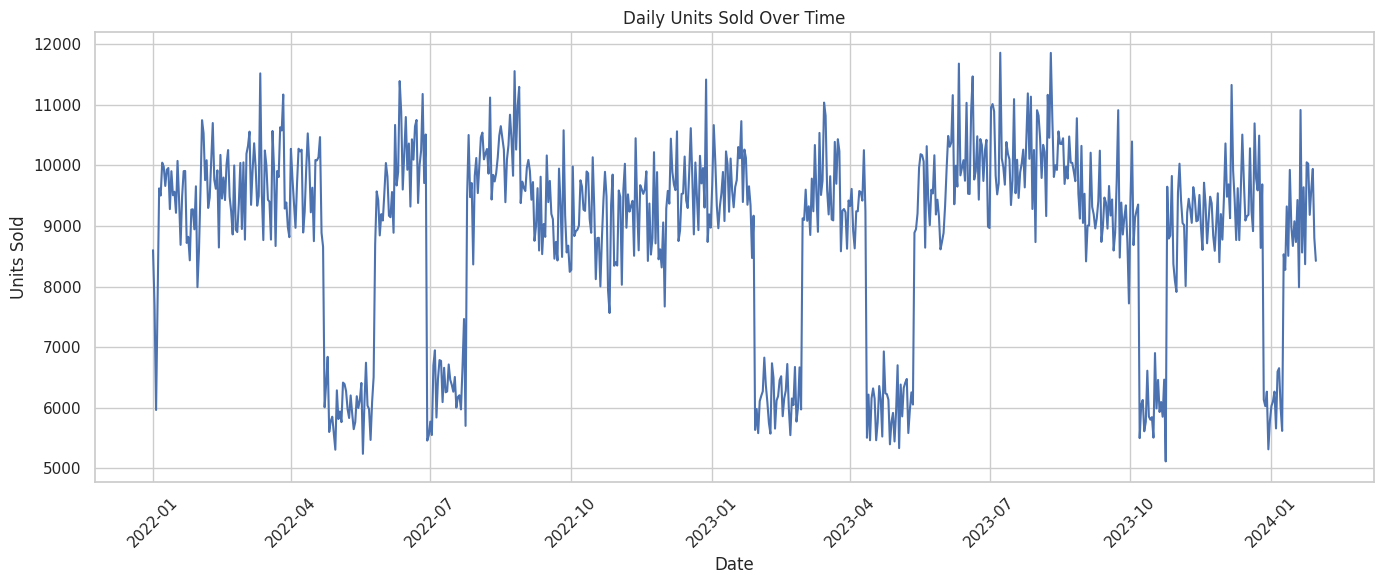

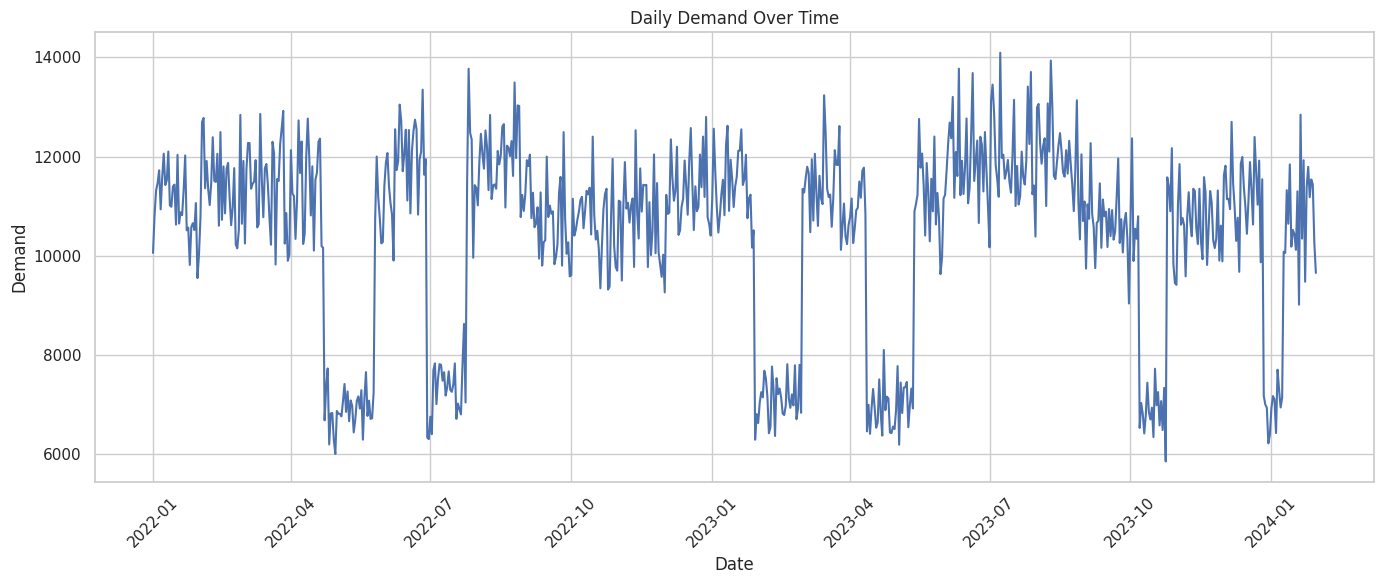

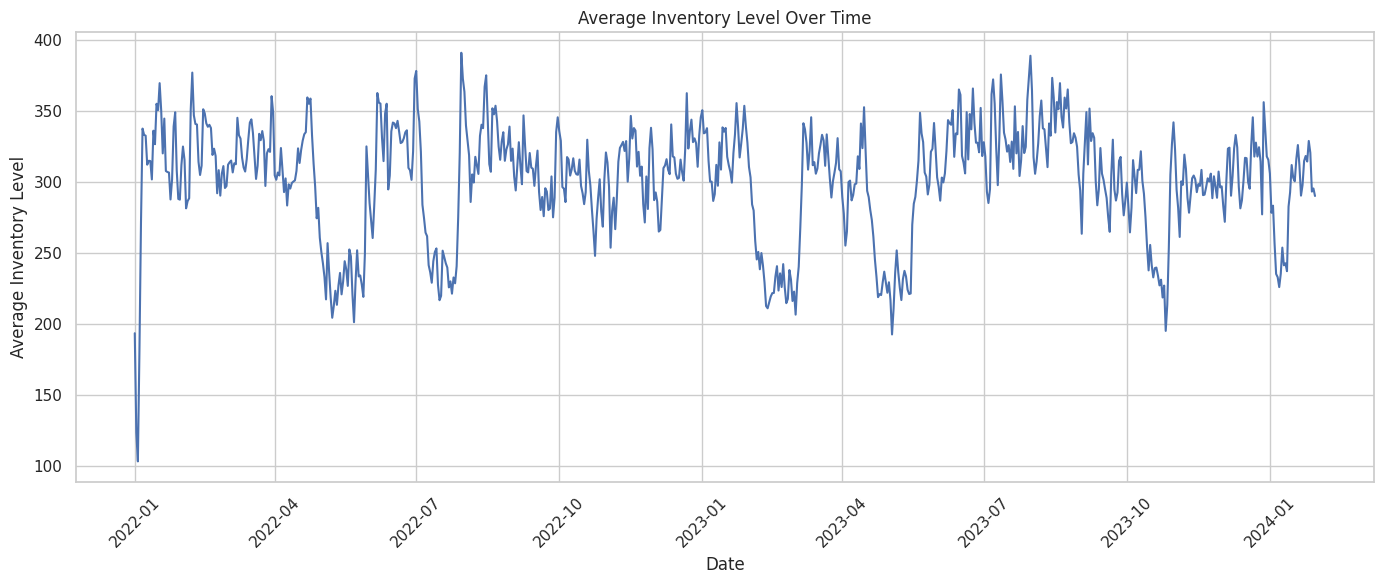

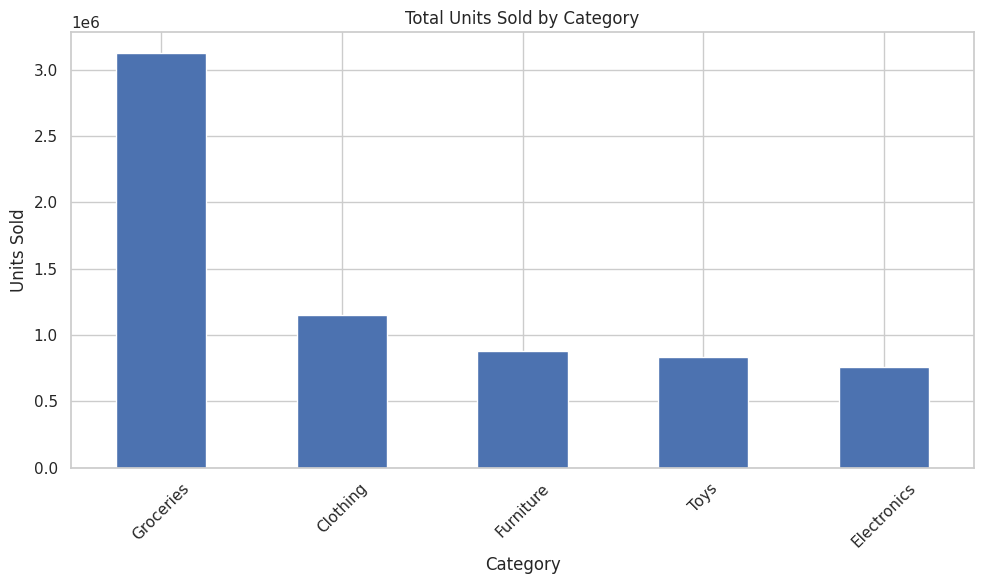

,Total Units Sold
Category,
Groceries,3127335.0
Clothing,1150873.0
Furniture,880654.0
Toys,834679.0
Electronics,757335.0


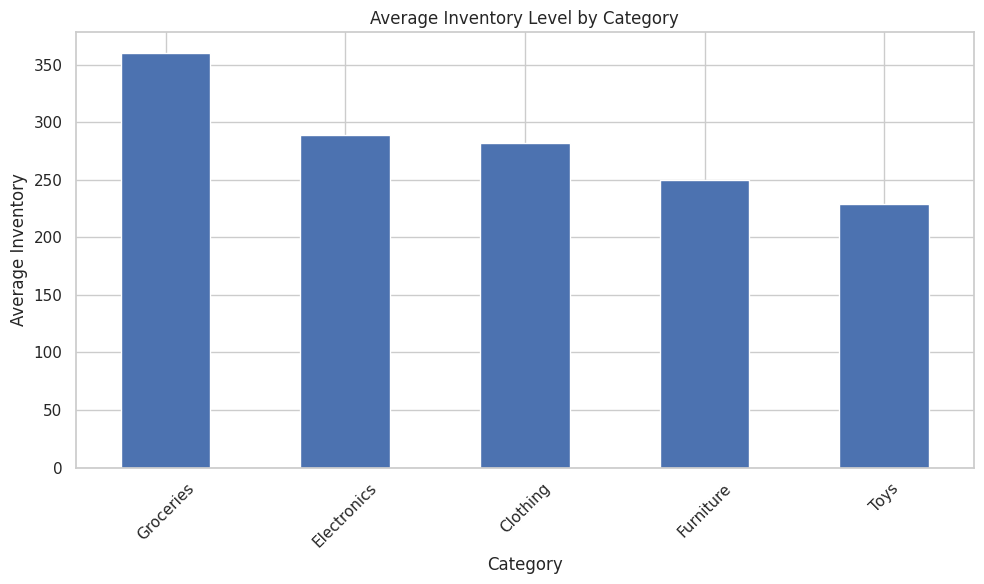

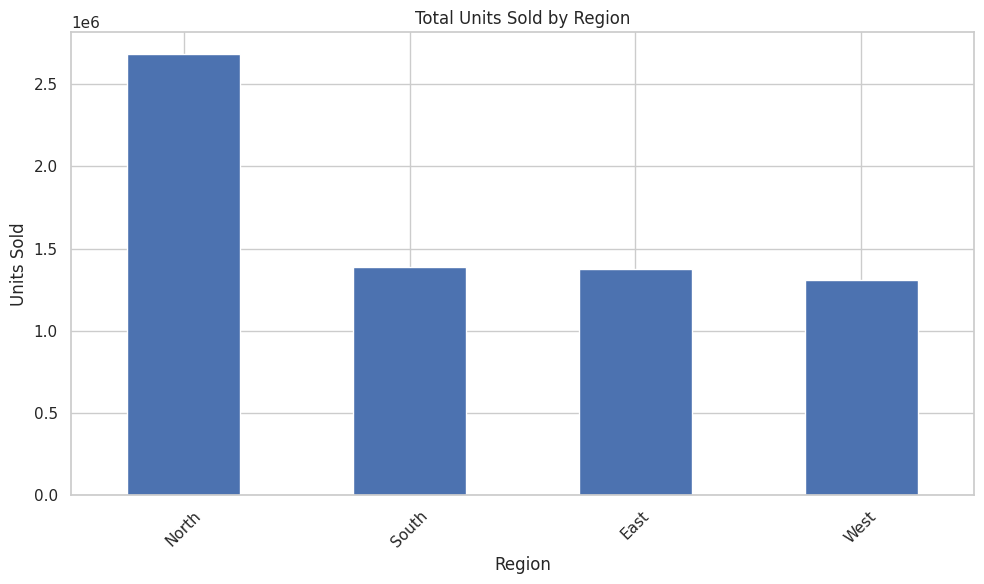

,Total Units Sold
Region,
North,2680946.0
South,1386126.0
East,1375613.0
West,1308191.0


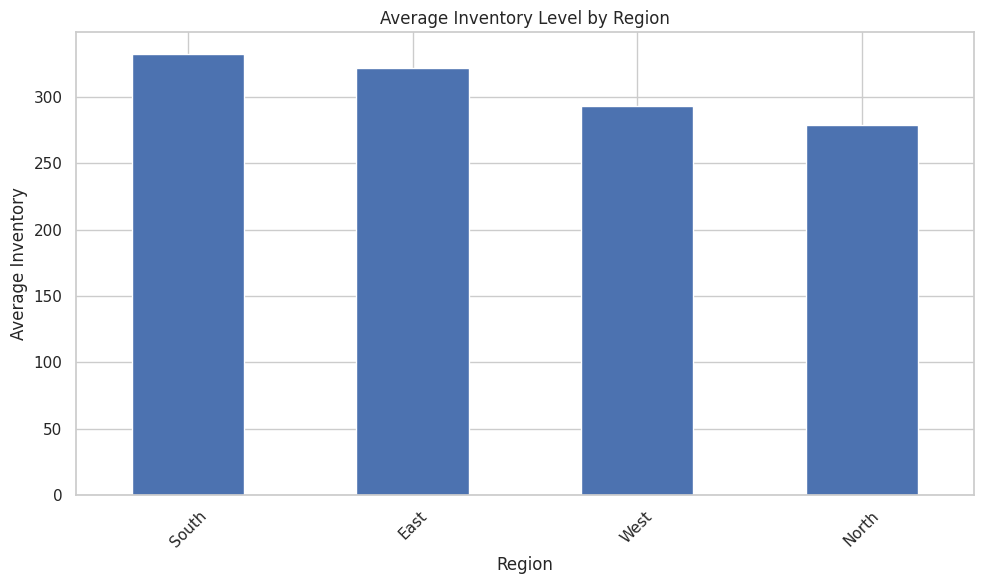

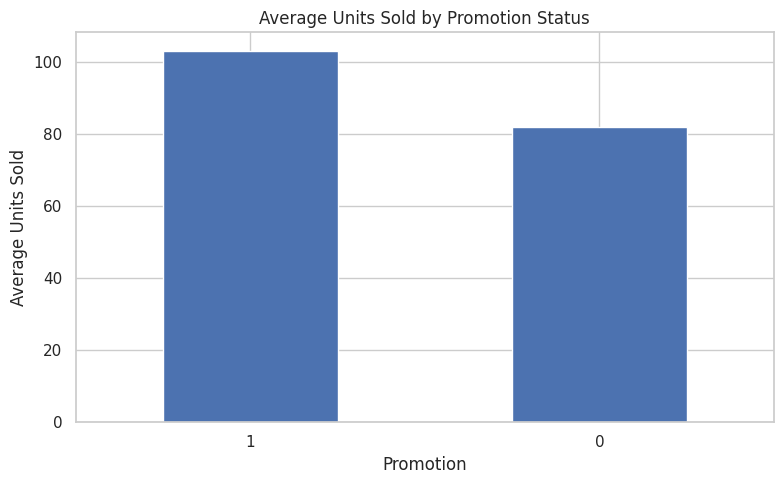

,Average Units Sold
Promotion,
1,103.095080
0,81.833314


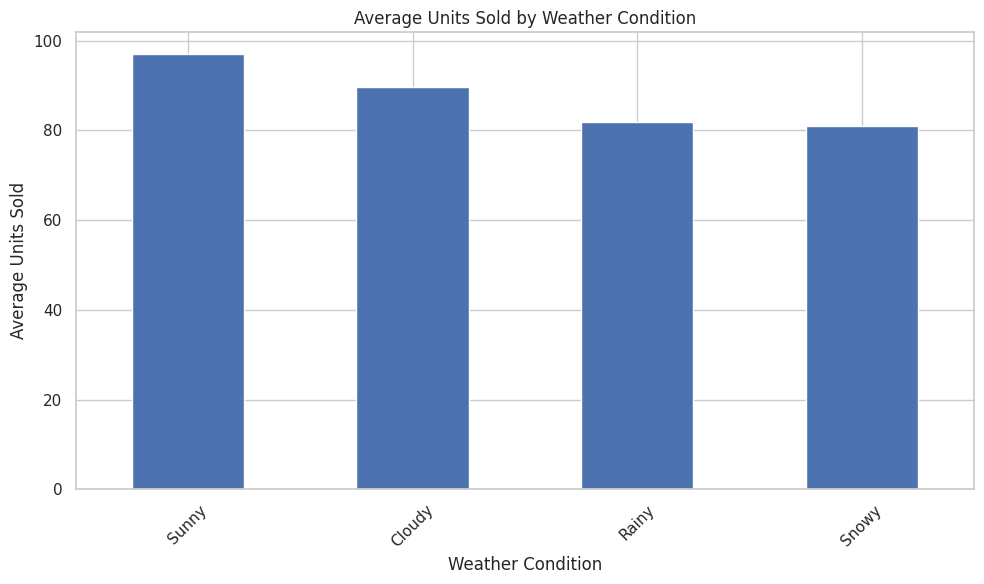

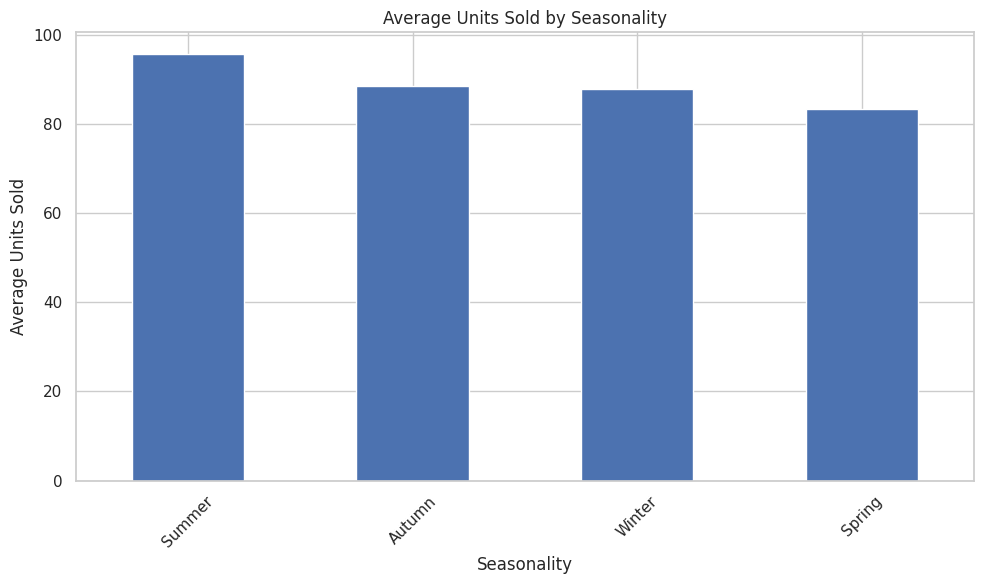

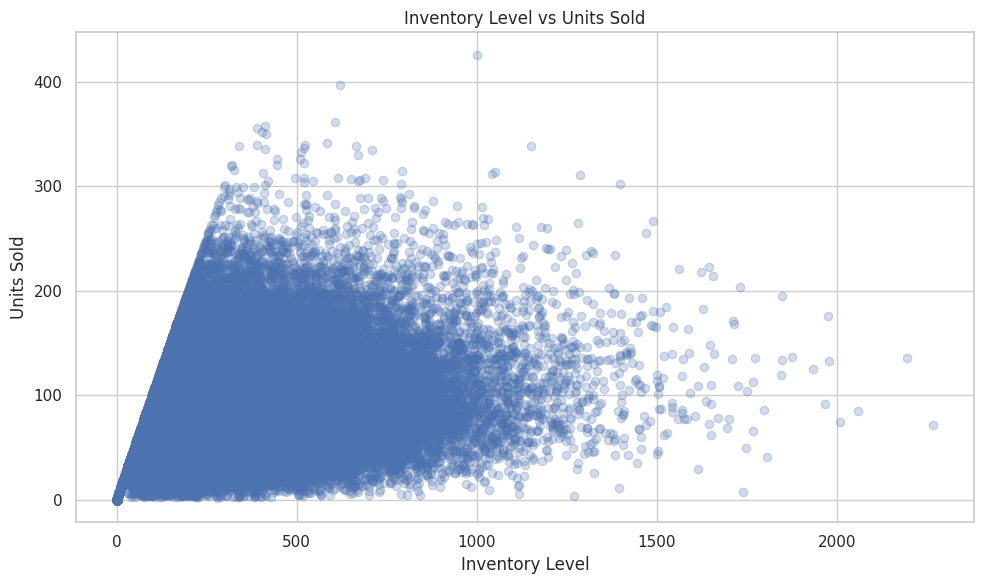

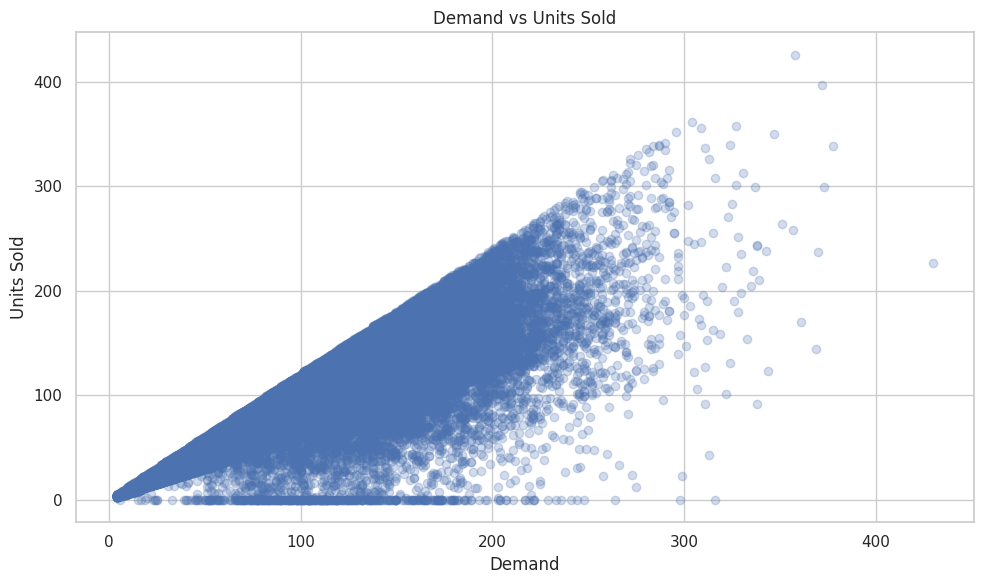


NUMERICAL FEATURE CORRELATION


,Inventory Level,Units Sold,Units Ordered,Price,Discount,Competitor Pricing,Epidemic,Demand
Inventory Level,1.00,0.23,-0.03,-0.04,-0.00,-0.03,-0.10,0.13
Units Sold,0.23,1.00,0.43,-0.01,0.18,-0.01,-0.32,0.83
Units Ordered,-0.03,0.43,1.00,0.04,0.17,0.05,-0.10,0.51
Price,-0.04,-0.01,0.04,1.00,-0.09,0.98,-0.09,-0.02
Discount,-0.00,0.18,0.17,-0.09,1.00,-0.09,-0.00,0.22
Competitor Pricing,-0.03,-0.01,0.05,0.98,-0.09,1.00,-0.09,-0.02
Epidemic,-0.10,-0.32,-0.10,-0.09,-0.00,-0.09,1.00,-0.36
Demand,0.13,0.83,0.51,-0.02,0.22,-0.02,-0.36,1.00


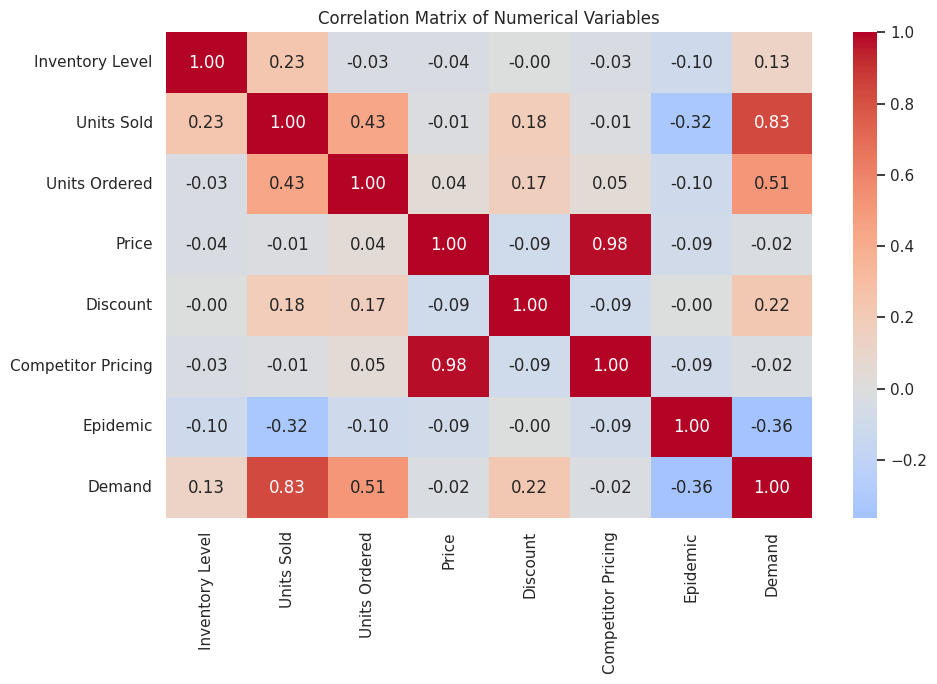


SALES-TO-INVENTORY RATIO BY CATEGORY


,Average Sales-to-Inventory Ratio
Category,
Clothing,0.509811
Toys,0.464901
Electronics,0.428702
Groceries,0.421094
Furniture,0.361853



KEY DATASET INSIGHTS
• Category with highest total sales       : Groceries
• Category with highest average inventory : Groceries
• Region with highest total sales         : North
• Region with highest average inventory   : South
• Highest average sales during promotion : 1
• Highest average sales season            : Summer

EDA SUMMARY


,Metric,Result
0,Highest Sales Category,Groceries
1,Highest Inventory Category,Groceries
2,Highest Sales Region,North
3,Highest Inventory Region,South
4,Highest Promotion Sales Group,1
5,Highest Sales Season,Summer



BLOCK 4 COMPLETED SUCCESSFULLY

✓ Exploratory analysis completed.
✓ Business patterns identified.
✓ Ready for feature engineering and future waste-risk target creation.


In [5]:
# ==========================================================
# Inventory Management
# BLOCK 4 - Exploratory Data Analysis & Business Insights
# ==========================================================

print("=" * 70)
print("BLOCK 4 - EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# ----------------------------------------------------------
# 1. Dataset Overview
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("DATASET OVERVIEW")
print("=" * 70)

print(f"Total Records : {len(inventory_df):,}")
print(f"Total Stores  : {inventory_df['Store ID'].nunique()}")
print(f"Total Products: {inventory_df['Product ID'].nunique()}")
print(f"Categories    : {inventory_df['Category'].nunique()}")
print(f"Regions       : {inventory_df['Region'].nunique()}")

print("\nCategories:")
print(inventory_df["Category"].unique())

print("\nRegions:")
print(inventory_df["Region"].unique())


# ----------------------------------------------------------
# 2. Daily Sales Trend
# ----------------------------------------------------------

daily_sales = (
    inventory_df
    .groupby("Date")["Units Sold"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_sales["Date"],
    daily_sales["Units Sold"]
)

plt.title("Daily Units Sold Over Time")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 3. Daily Demand Trend
# ----------------------------------------------------------

daily_demand = (
    inventory_df
    .groupby("Date")["Demand"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_demand["Date"],
    daily_demand["Demand"]
)

plt.title("Daily Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 4. Inventory Level Over Time
# ----------------------------------------------------------

daily_inventory = (
    inventory_df
    .groupby("Date")["Inventory Level"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_inventory["Date"],
    daily_inventory["Inventory Level"]
)

plt.title("Average Inventory Level Over Time")
plt.xlabel("Date")
plt.ylabel("Average Inventory Level")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 5. Sales by Category
# ----------------------------------------------------------

category_sales = (
    inventory_df
    .groupby("Category")["Units Sold"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

category_sales.plot(
    kind="bar"
)

plt.title("Total Units Sold by Category")
plt.xlabel("Category")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(category_sales.to_frame("Total Units Sold"))


# ----------------------------------------------------------
# 6. Inventory by Category
# ----------------------------------------------------------

category_inventory = (
    inventory_df
    .groupby("Category")["Inventory Level"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

category_inventory.plot(
    kind="bar"
)

plt.title("Average Inventory Level by Category")
plt.xlabel("Category")
plt.ylabel("Average Inventory")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 7. Sales by Region
# ----------------------------------------------------------

region_sales = (
    inventory_df
    .groupby("Region")["Units Sold"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

region_sales.plot(
    kind="bar"
)

plt.title("Total Units Sold by Region")
plt.xlabel("Region")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(region_sales.to_frame("Total Units Sold"))


# ----------------------------------------------------------
# 8. Average Inventory by Region
# ----------------------------------------------------------

region_inventory = (
    inventory_df
    .groupby("Region")["Inventory Level"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

region_inventory.plot(
    kind="bar"
)

plt.title("Average Inventory Level by Region")
plt.xlabel("Region")
plt.ylabel("Average Inventory")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 9. Promotion vs Sales
# ----------------------------------------------------------

promotion_sales = (
    inventory_df
    .groupby("Promotion")["Units Sold"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

promotion_sales.plot(
    kind="bar"
)

plt.title("Average Units Sold by Promotion Status")
plt.xlabel("Promotion")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(
    promotion_sales.to_frame("Average Units Sold")
)


# ----------------------------------------------------------
# 10. Weather vs Sales
# ----------------------------------------------------------

weather_sales = (
    inventory_df
    .groupby("Weather Condition")["Units Sold"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

weather_sales.plot(
    kind="bar"
)

plt.title("Average Units Sold by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 11. Seasonality vs Sales
# ----------------------------------------------------------

season_sales = (
    inventory_df
    .groupby("Seasonality")["Units Sold"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

season_sales.plot(
    kind="bar"
)

plt.title("Average Units Sold by Seasonality")
plt.xlabel("Seasonality")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 12. Inventory vs Units Sold
# ----------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    inventory_df["Inventory Level"],
    inventory_df["Units Sold"],
    alpha=0.25
)

plt.title("Inventory Level vs Units Sold")
plt.xlabel("Inventory Level")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 13. Demand vs Units Sold
# ----------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    inventory_df["Demand"],
    inventory_df["Units Sold"],
    alpha=0.25
)

plt.title("Demand vs Units Sold")
plt.xlabel("Demand")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 14. Correlation Analysis
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("NUMERICAL FEATURE CORRELATION")
print("=" * 70)

correlation_columns = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Epidemic",
    "Demand"
]

correlation_matrix = (
    inventory_df[correlation_columns]
    .corr()
)

display(correlation_matrix.round(2))

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 15. Inventory-Sales Efficiency
# ----------------------------------------------------------

inventory_df["Sales_to_Inventory_Ratio"] = (
    inventory_df["Units Sold"]
    / (inventory_df["Inventory Level"] + 1)
)

efficiency_summary = (
    inventory_df
    .groupby("Category")["Sales_to_Inventory_Ratio"]
    .mean()
    .sort_values(ascending=False)
)

print("\n" + "=" * 70)
print("SALES-TO-INVENTORY RATIO BY CATEGORY")
print("=" * 70)

display(
    efficiency_summary.to_frame(
        "Average Sales-to-Inventory Ratio"
    )
)


# ----------------------------------------------------------
# 16. Basic Business Insights
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("KEY DATASET INSIGHTS")
print("=" * 70)

highest_sales_category = category_sales.idxmax()
highest_inventory_category = category_inventory.idxmax()
highest_sales_region = region_sales.idxmax()
highest_inventory_region = region_inventory.idxmax()

print(
    f"• Category with highest total sales       : "
    f"{highest_sales_category}"
)

print(
    f"• Category with highest average inventory : "
    f"{highest_inventory_category}"
)

print(
    f"• Region with highest total sales         : "
    f"{highest_sales_region}"
)

print(
    f"• Region with highest average inventory   : "
    f"{highest_inventory_region}"
)

print(
    f"• Highest average sales during promotion : "
    f"{promotion_sales.idxmax()}"
)

print(
    f"• Highest average sales season            : "
    f"{season_sales.idxmax()}"
)


# ----------------------------------------------------------
# 17. Save EDA Summary
# ----------------------------------------------------------

eda_summary = {
    "Highest Sales Category": highest_sales_category,
    "Highest Inventory Category": highest_inventory_category,
    "Highest Sales Region": highest_sales_region,
    "Highest Inventory Region": highest_inventory_region,
    "Highest Promotion Sales Group": promotion_sales.idxmax(),
    "Highest Sales Season": season_sales.idxmax()
}

eda_summary_df = pd.DataFrame(
    eda_summary.items(),
    columns=["Metric", "Result"]
)

print("\n" + "=" * 70)
print("EDA SUMMARY")
print("=" * 70)

display(eda_summary_df)


print("\n" + "=" * 70)
print("BLOCK 4 COMPLETED SUCCESSFULLY")
print("=" * 70)

print(
    "\n✓ Exploratory analysis completed."
)
print(
    "✓ Business patterns identified."
)
print(
    "✓ Ready for feature engineering and future waste-risk target creation."
)

Generating Business Intelligence Dashboard...


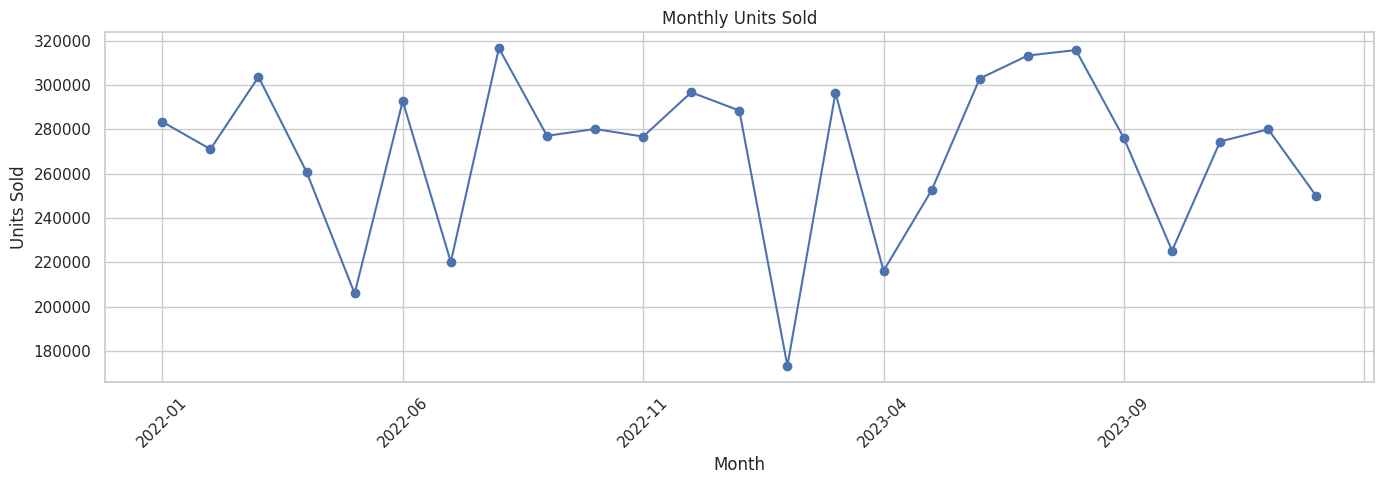

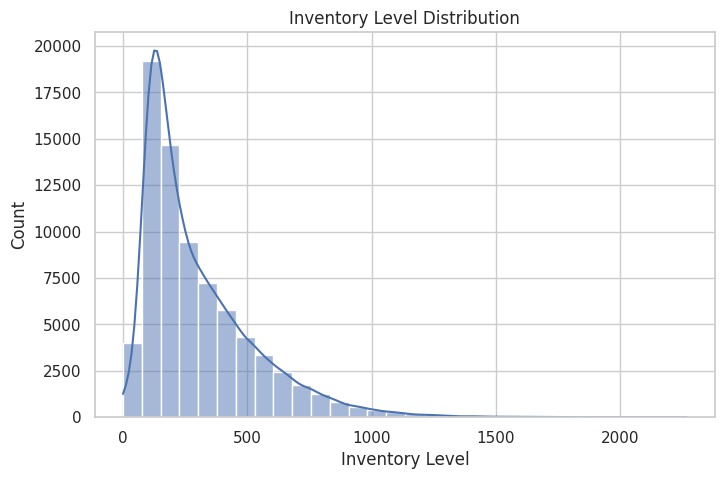

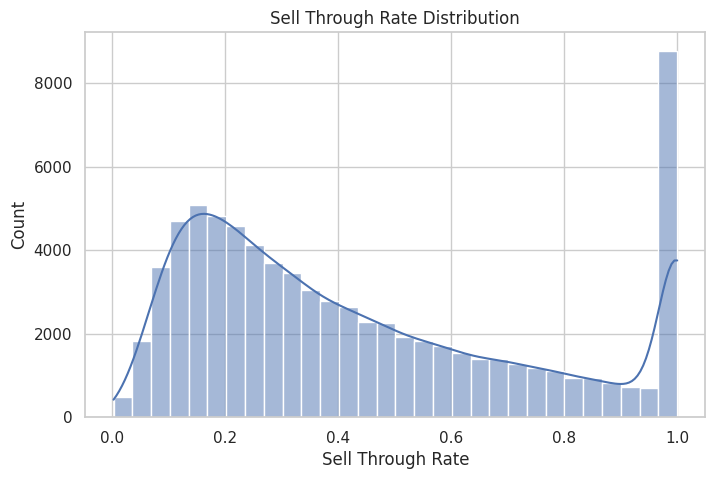

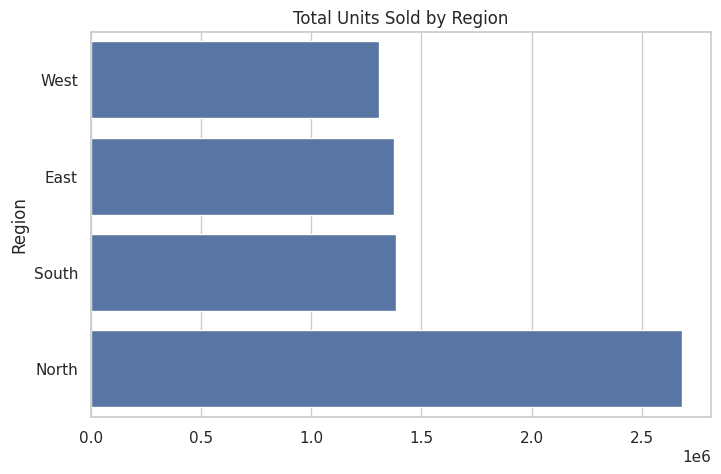

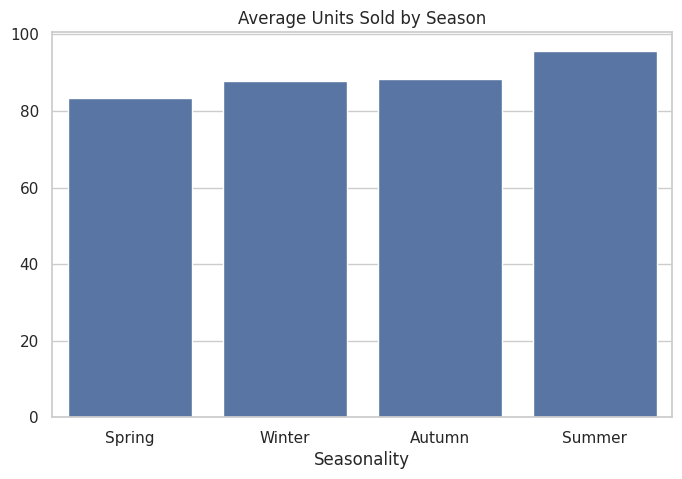

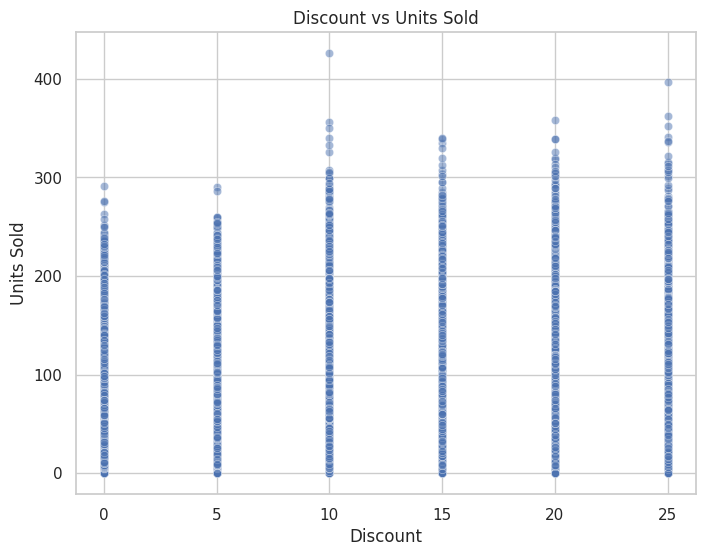


Skipping Price vs Demand Forecast chart: 'Demand Forecast' column is not available.


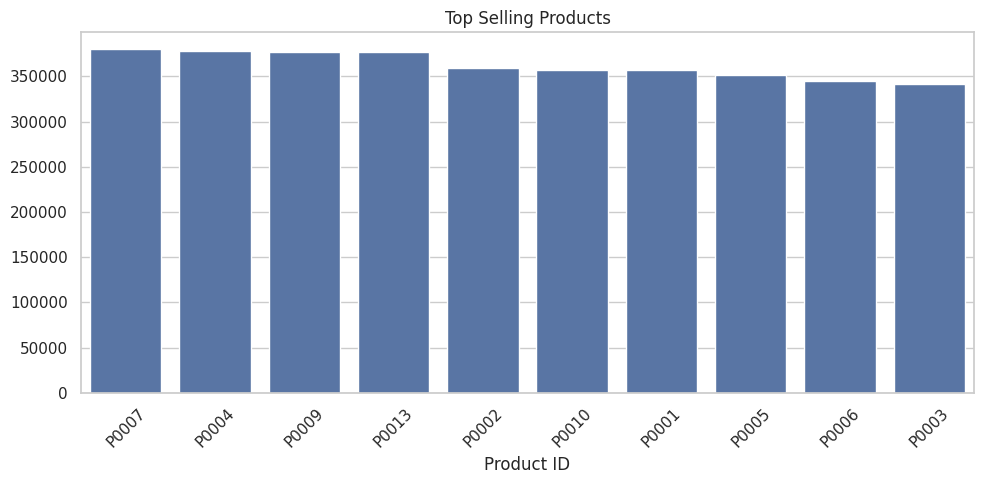

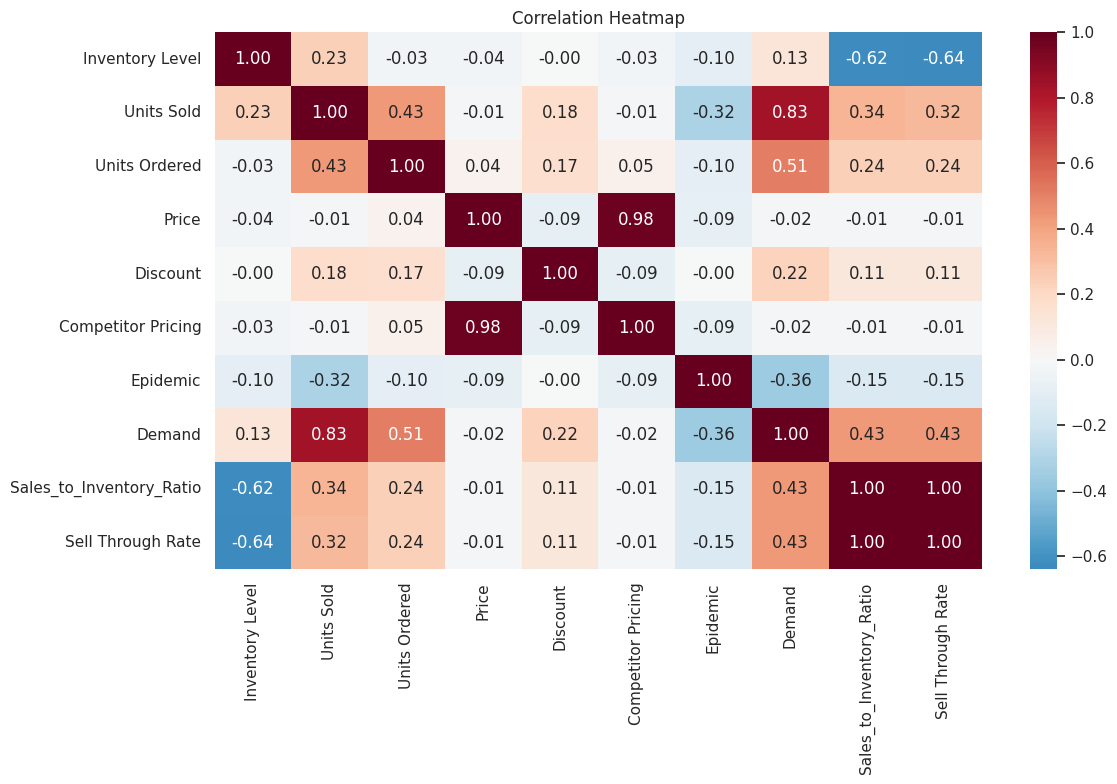



Business KPI Summary


,Metric,Value
0,Total Inventory,2.288078e+07
1,Total Units Sold,6.750876e+06
2,Average Sell Through,4.380000e-01
3,Average Discount,9.090000e+00
4,Average Price,6.773000e+01



EDA Dashboard Completed Successfully.


In [8]:

# ==========================================================
# Inventory Management
# Block 4 - Business Data Insights Dashboard
# ==========================================================

print("="*70)
print("Generating Business Intelligence Dashboard...")
print("="*70)

eda_df = inventory_df.copy()

# ----------------------------------------------------------
# Business Feature
# Sell Through Rate
# ----------------------------------------------------------

eda_df["Sell Through Rate"] = (
    eda_df["Units Sold"] /
    eda_df["Inventory Level"].replace(0, np.nan)
).clip(upper=1)

# ----------------------------------------------------------
# Ensure YearMonth Exists
# ----------------------------------------------------------

if "YearMonth" not in eda_df.columns:
    eda_df["Date"] = pd.to_datetime(eda_df["Date"])
    eda_df["YearMonth"] = eda_df["Date"].dt.to_period("M").astype(str)

# ----------------------------------------------------------
# Monthly Sales Trend
# ----------------------------------------------------------

monthly_sales = (
    eda_df.groupby("YearMonth")["Units Sold"].sum()
)

plt.figure(figsize=(14,5))
monthly_sales.plot(marker="o")
plt.title("Monthly Units Sold")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# Inventory Distribution
# ----------------------------------------------------------

plt.figure(figsize=(8,5))
sns.histplot(eda_df["Inventory Level"], bins=30, kde=True)
plt.title("Inventory Level Distribution")
plt.show()

# ----------------------------------------------------------
# Sell Through Distribution
# ----------------------------------------------------------

plt.figure(figsize=(8,5))
sns.histplot(eda_df["Sell Through Rate"], bins=30, kde=True)
plt.title("Sell Through Rate Distribution")
plt.show()

# ----------------------------------------------------------
# Regional Sales
# ----------------------------------------------------------

plt.figure(figsize=(8,5))

region_sales = (
    eda_df.groupby("Region")["Units Sold"]
    .sum()
    .sort_values()
)

sns.barplot(x=region_sales.values, y=region_sales.index)
plt.title("Total Units Sold by Region")
plt.show()

# ----------------------------------------------------------
# Seasonal Demand
# ----------------------------------------------------------

plt.figure(figsize=(8,5))

season_sales = (
    eda_df.groupby("Seasonality")["Units Sold"]
    .mean()
    .sort_values()
)

sns.barplot(x=season_sales.index, y=season_sales.values)
plt.title("Average Units Sold by Season")
plt.show()

# ----------------------------------------------------------
# Discount vs Sales
# ----------------------------------------------------------

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=eda_df,
    x="Discount",
    y="Units Sold",
    alpha=.5
)
plt.title("Discount vs Units Sold")
plt.show()

# ----------------------------------------------------------
# Price vs Demand Forecast
# ----------------------------------------------------------

if "Demand Forecast" in eda_df.columns:

    plt.figure(figsize=(8,6))
    sns.scatterplot(
        data=eda_df,
        x="Price",
        y="Demand Forecast",
        alpha=.5
    )
    plt.title("Price vs Demand Forecast")
    plt.tight_layout()
    plt.show()

else:
    print(
        "\nSkipping Price vs Demand Forecast chart: "
        "'Demand Forecast' column is not available."
    )

# ----------------------------------------------------------
# Top Selling Products
# ----------------------------------------------------------

top_products = (
    eda_df.groupby("Product ID")["Units Sold"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))
sns.barplot(x=top_products.index, y=top_products.values)
plt.title("Top Selling Products")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# Correlation Heatmap
# ----------------------------------------------------------

numeric_df = eda_df.select_dtypes(include=np.number)

plt.figure(figsize=(12,8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="RdBu_r",
    center=0,
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# Executive KPI Dashboard
# ----------------------------------------------------------

print("\n")
print("="*70)
print("Business KPI Summary")
print("="*70)

metrics = [
    "Total Inventory",
    "Total Units Sold",
    "Average Sell Through",
    "Average Discount",
    "Average Price"
]

values = [
    int(eda_df["Inventory Level"].sum()),
    int(eda_df["Units Sold"].sum()),
    round(eda_df["Sell Through Rate"].mean(), 3),
    round(eda_df["Discount"].mean(), 2),
    round(eda_df["Price"].mean(), 2)
]

if "Demand Forecast" in eda_df.columns:
    metrics.insert(3, "Average Forecast")
    values.insert(3, round(eda_df["Demand Forecast"].mean(), 2))

kpi = pd.DataFrame({
    "Metric": metrics,
    "Value": values
})

display(kpi)

print("\nEDA Dashboard Completed Successfully.")


BLOCK 5 - FEATURE ENGINEERING & WASTE RISK TARGET

Starting records: 76,000

Rows removed because a complete future 7-day window was unavailable: 700

WASTE RISK DISTRIBUTION


,Records,Percentage
Waste Risk,,
Low,63485,84.31
Medium,8345,11.08
High,3470,4.61


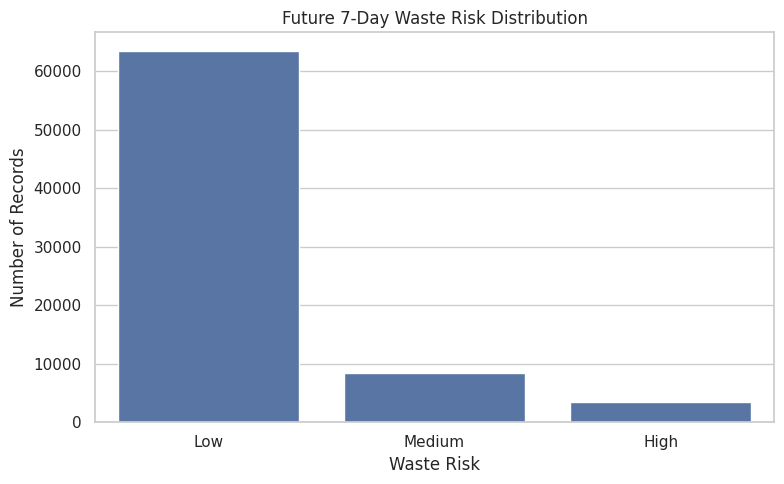


ENGINEERED FEATURES
✓ Day
✓ DayOfWeek
✓ Month
✓ Quarter
✓ WeekOfYear
✓ IsWeekend
✓ Inventory_to_Demand
✓ Inventory_to_Sales
✓ Order_to_Sales
✓ Price_Gap
✓ Previous_Day_Sales
✓ Previous_7D_Average_Sales
✓ Previous_7D_Max_Sales
✓ Previous_7D_Sales
✓ Previous_Day_Demand
✓ Previous_7D_Average_Demand
✓ Previous_Day_Inventory
✓ Previous_7D_Average_Inventory

FINAL FEATURE DATASET
Rows    : 75,300
Columns : 40

Target Variable:
Waste Risk

Target Classes:
['Low' 'Medium' 'High']

BLOCK 5 COMPLETED SUCCESSFULLY

✓ Historical features created
✓ Future 7-day outcome calculated
✓ Waste-risk target created
✓ Future rows without complete 7-day windows removed
✓ Feature dataset saved as: feature_engineered_df

Ready for Block 6 - Feature Selection & Chronological Train/Test Split.


In [9]:
# ==========================================================
# Inventory Management
# BLOCK 5 - Feature Engineering & Future Waste Risk Target
# ==========================================================

print("=" * 70)
print("BLOCK 5 - FEATURE ENGINEERING & WASTE RISK TARGET")
print("=" * 70)

# ----------------------------------------------------------
# 1. Create feature engineering dataset
# ----------------------------------------------------------

model_df = inventory_df.copy()

# Make sure data is correctly ordered
model_df = model_df.sort_values(
    by=["Store ID", "Product ID", "Date"]
).reset_index(drop=True)

print(f"\nStarting records: {len(model_df):,}")


# ----------------------------------------------------------
# 2. Calendar Features
# ----------------------------------------------------------

model_df["Day"] = model_df["Date"].dt.day
model_df["DayOfWeek"] = model_df["Date"].dt.dayofweek
model_df["Month"] = model_df["Date"].dt.month
model_df["Quarter"] = model_df["Date"].dt.quarter
model_df["WeekOfYear"] = model_df["Date"].dt.isocalendar().week.astype(int)

model_df["IsWeekend"] = (
    model_df["DayOfWeek"] >= 5
).astype(int)


# ----------------------------------------------------------
# 3. Current Inventory Features
# ----------------------------------------------------------

model_df["Inventory_to_Demand"] = (
    model_df["Inventory Level"]
    / (model_df["Demand"] + 1)
)

model_df["Inventory_to_Sales"] = (
    model_df["Inventory Level"]
    / (model_df["Units Sold"] + 1)
)

model_df["Order_to_Sales"] = (
    model_df["Units Ordered"]
    / (model_df["Units Sold"] + 1)
)

model_df["Price_Gap"] = (
    model_df["Price"]
    - model_df["Competitor Pricing"]
)


# ----------------------------------------------------------
# 4. Historical Sales Features
# ----------------------------------------------------------
# IMPORTANT:
# These use ONLY previous observations.
# No future information is used here.

group_columns = ["Store ID", "Product ID"]

grouped_sales = model_df.groupby(group_columns)["Units Sold"]

model_df["Previous_Day_Sales"] = (
    grouped_sales
    .shift(1)
)

model_df["Previous_7D_Average_Sales"] = (
    grouped_sales
    .transform(
        lambda x:
        x.shift(1)
        .rolling(7, min_periods=1)
        .mean()
    )
)

model_df["Previous_7D_Max_Sales"] = (
    grouped_sales
    .transform(
        lambda x:
        x.shift(1)
        .rolling(7, min_periods=1)
        .max()
    )
)

model_df["Previous_7D_Sales"] = (
    grouped_sales
    .transform(
        lambda x:
        x.shift(1)
        .rolling(7, min_periods=1)
        .sum()
    )
)


# ----------------------------------------------------------
# 5. Historical Demand Features
# ----------------------------------------------------------

grouped_demand = model_df.groupby(group_columns)["Demand"]

model_df["Previous_Day_Demand"] = (
    grouped_demand.shift(1)
)

model_df["Previous_7D_Average_Demand"] = (
    grouped_demand
    .transform(
        lambda x:
        x.shift(1)
        .rolling(7, min_periods=1)
        .mean()
    )
)


# ----------------------------------------------------------
# 6. Historical Inventory Features
# ----------------------------------------------------------

grouped_inventory = model_df.groupby(group_columns)["Inventory Level"]

model_df["Previous_Day_Inventory"] = (
    grouped_inventory.shift(1)
)

model_df["Previous_7D_Average_Inventory"] = (
    grouped_inventory
    .transform(
        lambda x:
        x.shift(1)
        .rolling(7, min_periods=1)
        .mean()
    )
)


# ----------------------------------------------------------
# 7. Future 7-Day Sales
# ----------------------------------------------------------
# This is used ONLY to create the target.
#
# We are asking:
# "Based on today's information, will this item have
#  excessive inventory relative to the sales expected
#  over the next 7 days?"
#
# Future values are NEVER used as model features.

def calculate_future_7d_sum(series):
    return (
        series
        .shift(-1)
        .rolling(
            window=7,
            min_periods=7
        )
        .sum()
        .shift(-6)
    )


model_df["Future_7D_Sales"] = (
    model_df
    .groupby(group_columns)["Units Sold"]
    .transform(calculate_future_7d_sum)
)


# ----------------------------------------------------------
# 8. Future 7-Day Orders
# ----------------------------------------------------------

model_df["Future_7D_Orders"] = (
    model_df
    .groupby(group_columns)["Units Ordered"]
    .transform(calculate_future_7d_sum)
)


# ----------------------------------------------------------
# 9. Future Inventory Position
# ----------------------------------------------------------
# Approximation:
#
# Future Inventory =
# Current Inventory
# + Future Orders
# - Future Sales

model_df["Future_Inventory_Position"] = (
    model_df["Inventory Level"]
    + model_df["Future_7D_Orders"]
    - model_df["Future_7D_Sales"]
)


# ----------------------------------------------------------
# 10. Future Inventory-to-Sales Ratio
# ----------------------------------------------------------

model_df["Future_Inventory_Ratio"] = (
    model_df["Future_Inventory_Position"]
    / (model_df["Future_7D_Sales"] + 1)
)


# ----------------------------------------------------------
# 11. Create Waste Risk Target
# ----------------------------------------------------------
#
# LOW:
# Future inventory is relatively aligned with future sales.
#
# MEDIUM:
# Future inventory is higher than expected demand.
#
# HIGH:
# Future inventory is substantially higher than
# expected demand.
#
# This is an operational proxy because the dataset
# does not contain an actual "waste" column.

def assign_waste_risk(row):

    future_sales = row["Future_7D_Sales"]
    future_inventory = row["Future_Inventory_Position"]

    if pd.isna(future_sales) or pd.isna(future_inventory):
        return np.nan

    if future_inventory <= future_sales:
        return "Low"

    elif future_inventory <= 1.5 * future_sales:
        return "Medium"

    else:
        return "High"


model_df["Waste Risk"] = model_df.apply(
    assign_waste_risk,
    axis=1
)


# ----------------------------------------------------------
# 12. Remove Rows Without Complete Future Window
# ----------------------------------------------------------

rows_before_target_cleaning = len(model_df)

model_df = model_df.dropna(
    subset=[
        "Future_7D_Sales",
        "Future_7D_Orders",
        "Future_Inventory_Position",
        "Waste Risk"
    ]
).reset_index(drop=True)

rows_removed = (
    rows_before_target_cleaning
    - len(model_df)
)

print(
    f"\nRows removed because a complete future "
    f"7-day window was unavailable: {rows_removed:,}"
)


# ----------------------------------------------------------
# 13. Check Target Distribution
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("WASTE RISK DISTRIBUTION")
print("=" * 70)

risk_distribution = (
    model_df["Waste Risk"]
    .value_counts()
)

risk_percentage = (
    model_df["Waste Risk"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

risk_summary = pd.DataFrame({
    "Records": risk_distribution,
    "Percentage": risk_percentage
})

display(risk_summary)


# ----------------------------------------------------------
# 14. Visualize Target Distribution
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.countplot(
    data=model_df,
    x="Waste Risk",
    order=["Low", "Medium", "High"]
)

plt.title("Future 7-Day Waste Risk Distribution")
plt.xlabel("Waste Risk")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 15. Feature Engineering Summary
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("ENGINEERED FEATURES")
print("=" * 70)

engineered_features = [
    "Day",
    "DayOfWeek",
    "Month",
    "Quarter",
    "WeekOfYear",
    "IsWeekend",
    "Inventory_to_Demand",
    "Inventory_to_Sales",
    "Order_to_Sales",
    "Price_Gap",
    "Previous_Day_Sales",
    "Previous_7D_Average_Sales",
    "Previous_7D_Max_Sales",
    "Previous_7D_Sales",
    "Previous_Day_Demand",
    "Previous_7D_Average_Demand",
    "Previous_Day_Inventory",
    "Previous_7D_Average_Inventory"
]

for feature in engineered_features:
    print("✓", feature)


# ----------------------------------------------------------
# 16. Check for Infinite Values
# ----------------------------------------------------------

model_df.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)


# ----------------------------------------------------------
# 17. Final Feature Dataset Information
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL FEATURE DATASET")
print("=" * 70)

print(f"Rows    : {model_df.shape[0]:,}")
print(f"Columns : {model_df.shape[1]}")

print("\nTarget Variable:")
print("Waste Risk")

print("\nTarget Classes:")
print(
    model_df["Waste Risk"]
    .unique()
)


# ----------------------------------------------------------
# 18. Save Feature Dataset
# ----------------------------------------------------------

feature_engineered_df = model_df.copy()


print("\n" + "=" * 70)
print("BLOCK 5 COMPLETED SUCCESSFULLY")
print("=" * 70)

print(
    "\n✓ Historical features created"
)

print(
    "✓ Future 7-day outcome calculated"
)

print(
    "✓ Waste-risk target created"
)

print(
    "✓ Future rows without complete 7-day windows removed"
)

print(
    "✓ Feature dataset saved as: feature_engineered_df"
)

print(
    "\nReady for Block 6 - Feature Selection & "
    "Chronological Train/Test Split."
)

In [10]:
# ==========================================================
# Inventory Management
# BLOCK 6 - Feature Selection & Chronological Train/Test Split
# ==========================================================

print("=" * 70)
print("BLOCK 6 - FEATURE SELECTION & TRAIN/TEST SPLIT")
print("=" * 70)


# ----------------------------------------------------------
# 1. Work with feature-engineered dataset
# ----------------------------------------------------------

ml_df = feature_engineered_df.copy()

# Sort again to guarantee chronological order
ml_df = ml_df.sort_values(
    by="Date"
).reset_index(drop=True)

print(f"\nTotal ML records: {len(ml_df):,}")


# ----------------------------------------------------------
# 2. Define Target Variable
# ----------------------------------------------------------

TARGET = "Waste Risk"

print("\nTarget variable:")
print(TARGET)


# ----------------------------------------------------------
# 3. Define Features
# ----------------------------------------------------------
#
# IMPORTANT:
# Future_7D_Sales
# Future_7D_Orders
# Future_Inventory_Position
# Future_Inventory_Ratio
#
# are NOT included because they contain future information.
#
# Waste Risk is also excluded because it is the target.

feature_columns = [

    # Current business information
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Epidemic",
    "Demand",

    # Categorical business information
    "Category",
    "Region",
    "Weather Condition",
    "Promotion",
    "Seasonality",

    # Calendar features
    "Day",
    "DayOfWeek",
    "Month",
    "Quarter",
    "WeekOfYear",
    "IsWeekend",

    # Current inventory relationships
    "Inventory_to_Demand",
    "Inventory_to_Sales",
    "Order_to_Sales",
    "Price_Gap",

    # Historical sales
    "Previous_Day_Sales",
    "Previous_7D_Average_Sales",
    "Previous_7D_Max_Sales",
    "Previous_7D_Sales",

    # Historical demand
    "Previous_Day_Demand",
    "Previous_7D_Average_Demand",

    # Historical inventory
    "Previous_Day_Inventory",
    "Previous_7D_Average_Inventory"
]


# ----------------------------------------------------------
# 4. Verify Features Exist
# ----------------------------------------------------------

missing_features = [
    feature
    for feature in feature_columns
    if feature not in ml_df.columns
]

if missing_features:
    raise ValueError(
        f"Missing required features: {missing_features}"
    )

print(f"\nNumber of selected features: {len(feature_columns)}")


# ----------------------------------------------------------
# 5. Create X and y
# ----------------------------------------------------------

X = ml_df[feature_columns].copy()
y = ml_df[TARGET].copy()


# ----------------------------------------------------------
# 6. Remove Rows with Missing Target
# ----------------------------------------------------------

valid_target = y.notna()

X = X.loc[valid_target].reset_index(drop=True)
y = y.loc[valid_target].reset_index(drop=True)

ml_df = ml_df.loc[
    valid_target
].reset_index(drop=True)


# ----------------------------------------------------------
# 7. Chronological 80/20 Split
# ----------------------------------------------------------
#
# We DO NOT use train_test_split(random_state=42)
# because this is time-dependent inventory data.
#
# Earlier records -> Training
# Later records  -> Testing

split_index = int(len(ml_df) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

train_df = ml_df.iloc[:split_index].copy()
test_df = ml_df.iloc[split_index:].copy()


# ----------------------------------------------------------
# 8. Display Split Information
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("CHRONOLOGICAL TRAIN/TEST SPLIT")
print("=" * 70)

print(f"\nTraining records : {len(X_train):,}")
print(f"Testing records  : {len(X_test):,}")

print(
    f"\nTraining period : "
    f"{train_df['Date'].min().date()} → "
    f"{train_df['Date'].max().date()}"
)

print(
    f"Testing period  : "
    f"{test_df['Date'].min().date()} → "
    f"{test_df['Date'].max().date()}"
)


# ----------------------------------------------------------
# 9. Verify No Date Overlap
# ----------------------------------------------------------

train_max_date = train_df["Date"].max()
test_min_date = test_df["Date"].min()

print("\nDate overlap check:")

if train_max_date < test_min_date:
    print("✓ No chronological overlap detected.")
else:
    print("⚠️ Check chronological split.")


# ----------------------------------------------------------
# 10. Training Target Distribution
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING TARGET DISTRIBUTION")
print("=" * 70)

train_distribution = pd.DataFrame({
    "Count": y_train.value_counts(),
    "Percentage": (
        y_train.value_counts(normalize=True) * 100
    ).round(2)
})

display(train_distribution)


# ----------------------------------------------------------
# 11. Testing Target Distribution
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("TESTING TARGET DISTRIBUTION")
print("=" * 70)

test_distribution = pd.DataFrame({
    "Count": y_test.value_counts(),
    "Percentage": (
        y_test.value_counts(normalize=True) * 100
    ).round(2)
})

display(test_distribution)


# ----------------------------------------------------------
# 12. Check Feature Types
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE TYPES")
print("=" * 70)

feature_type_summary = pd.DataFrame({
    "Feature": X_train.columns,
    "Data Type": [
        str(dtype)
        for dtype in X_train.dtypes
    ],
    "Missing Values": [
        X_train[col].isna().sum()
        for col in X_train.columns
    ]
})

display(feature_type_summary)


# ----------------------------------------------------------
# 13. Separate Numerical and Categorical Features
# ----------------------------------------------------------

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Features:")
for feature in categorical_features:
    print("  ✓", feature)

print("\nNumerical Features:")
for feature in numerical_features:
    print("  ✓", feature)


# ----------------------------------------------------------
# 14. Final Leakage Check
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("TARGET LEAKAGE CHECK")
print("=" * 70)

future_columns = [
    "Future_7D_Sales",
    "Future_7D_Orders",
    "Future_Inventory_Position",
    "Future_Inventory_Ratio",
    "Waste Risk"
]

leakage_columns_present = [
    column
    for column in future_columns
    if column in X_train.columns
]

if len(leakage_columns_present) == 0:
    print("✓ No future-derived target columns found in X.")
else:
    print(
        "⚠️ Potential leakage columns found:"
    )
    print(leakage_columns_present)


# ----------------------------------------------------------
# 15. Store Feature Names
# ----------------------------------------------------------

MODEL_FEATURES = feature_columns.copy()

print("\n" + "=" * 70)
print("FINAL MODEL DATASET")
print("=" * 70)

print(f"X_train shape : {X_train.shape}")
print(f"X_test shape  : {X_test.shape}")
print(f"y_train shape : {y_train.shape}")
print(f"y_test shape  : {y_test.shape}")

print(
    f"\nNumber of numerical features  : "
    f"{len(numerical_features)}"
)

print(
    f"Number of categorical features: "
    f"{len(categorical_features)}"
)


# ----------------------------------------------------------
# 16. Save Split Data
# ----------------------------------------------------------

split_data = {
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test
}


print("\n" + "=" * 70)
print("BLOCK 6 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\n✓ Features selected")
print("✓ Future leakage columns excluded")
print("✓ Chronological 80/20 split completed")
print("✓ Numerical and categorical features identified")
print("✓ Training and testing datasets ready")

print("\nReady for Block 7 - Preprocessing Pipeline.")

BLOCK 6 - FEATURE SELECTION & TRAIN/TEST SPLIT

Total ML records: 75,300

Target variable:
Waste Risk

Number of selected features: 31

CHRONOLOGICAL TRAIN/TEST SPLIT

Training records : 60,240
Testing records  : 15,060

Training period : 2022-01-01 → 2023-08-26
Testing period  : 2023-08-26 → 2024-01-23

Date overlap check:
⚠️ Check chronological split.

TRAINING TARGET DISTRIBUTION


,Count,Percentage
Waste Risk,,
Low,50825,84.37
Medium,6662,11.06
High,2753,4.57



TESTING TARGET DISTRIBUTION


,Count,Percentage
Waste Risk,,
Low,12660,84.06
Medium,1683,11.18
High,717,4.76



FEATURE TYPES


,Feature,Data Type,Missing Values
0,Inventory Level,float64,0
1,Units Sold,float64,0
2,Units Ordered,float64,0
3,Price,float64,0
4,Discount,int64,0
5,Competitor Pricing,float64,0
6,Epidemic,int64,0
7,Demand,float64,0
8,Category,object,0
9,Region,object,0



Categorical Features:
  ✓ Category
  ✓ Region
  ✓ Weather Condition
  ✓ Promotion
  ✓ Seasonality

Numerical Features:
  ✓ Inventory Level
  ✓ Units Sold
  ✓ Units Ordered
  ✓ Price
  ✓ Discount
  ✓ Competitor Pricing
  ✓ Epidemic
  ✓ Demand
  ✓ Day
  ✓ DayOfWeek
  ✓ Month
  ✓ Quarter
  ✓ WeekOfYear
  ✓ IsWeekend
  ✓ Inventory_to_Demand
  ✓ Inventory_to_Sales
  ✓ Order_to_Sales
  ✓ Price_Gap
  ✓ Previous_Day_Sales
  ✓ Previous_7D_Average_Sales
  ✓ Previous_7D_Max_Sales
  ✓ Previous_7D_Sales
  ✓ Previous_Day_Demand
  ✓ Previous_7D_Average_Demand
  ✓ Previous_Day_Inventory
  ✓ Previous_7D_Average_Inventory

TARGET LEAKAGE CHECK
✓ No future-derived target columns found in X.

FINAL MODEL DATASET
X_train shape : (60240, 31)
X_test shape  : (15060, 31)
y_train shape : (60240,)
y_test shape  : (15060,)

Number of numerical features  : 26
Number of categorical features: 5

BLOCK 6 COMPLETED SUCCESSFULLY

✓ Features selected
✓ Future leakage columns excluded
✓ Chronological 80/20 split comple

In [11]:
# ==========================================================
# Inventory Management
# BLOCK 7 - ML PREPROCESSING PIPELINE
# ==========================================================

print("=" * 70)
print("BLOCK 7 - PREPROCESSING PIPELINE")
print("=" * 70)


# ----------------------------------------------------------
# 1. Verify feature groups from Block 6
# ----------------------------------------------------------

print("\nNumerical features :", len(numerical_features))
print("Categorical features:", len(categorical_features))


# ----------------------------------------------------------
# 2. Numerical preprocessing
# ----------------------------------------------------------
#
# Missing numerical values:
# Median imputation
#
# Scaling:
# StandardScaler
#
# The imputer and scaler are fitted ONLY on training data
# through the Pipeline.

numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# ----------------------------------------------------------
# 3. Categorical preprocessing
# ----------------------------------------------------------
#
# Missing categorical values:
# Most frequent value
#
# Encoding:
# One-Hot Encoding
#
# handle_unknown="ignore" prevents errors when a category
# appears in the test set that was not present during training.

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)


# ----------------------------------------------------------
# 4. Combine preprocessing pipelines
# ----------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)


# ----------------------------------------------------------
# 5. Fit preprocessing ONLY on training data
# ----------------------------------------------------------

print("\nFitting preprocessing pipeline on training data...")

X_train_processed = preprocessor.fit_transform(
    X_train
)

X_test_processed = preprocessor.transform(
    X_test
)

print("✓ Preprocessing fitted successfully")


# ----------------------------------------------------------
# 6. Check processed dimensions
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("PROCESSED DATASET DIMENSIONS")
print("=" * 70)

print(
    f"Original training features : "
    f"{X_train.shape[1]}"
)

print(
    f"Original testing features  : "
    f"{X_test.shape[1]}"
)

print(
    f"Processed training features: "
    f"{X_train_processed.shape[1]}"
)

print(
    f"Processed testing features : "
    f"{X_test_processed.shape[1]}"
)


# ----------------------------------------------------------
# 7. Check missing values after preprocessing
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("MISSING VALUE CHECK")
print("=" * 70)

print(
    "Missing values in processed training data:",
    np.isnan(X_train_processed).sum()
)

print(
    "Missing values in processed testing data :",
    np.isnan(X_test_processed).sum()
)


# ----------------------------------------------------------
# 8. Check for infinite values
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("INFINITE VALUE CHECK")
print("=" * 70)

print(
    "Infinite values in training:",
    np.isinf(X_train_processed).sum()
)

print(
    "Infinite values in testing :",
    np.isinf(X_test_processed).sum()
)


# ----------------------------------------------------------
# 9. Get processed feature names
# ----------------------------------------------------------

processed_feature_names = (
    preprocessor
    .get_feature_names_out()
)

print("\n" + "=" * 70)
print("PROCESSED FEATURES")
print("=" * 70)

print(
    f"Total processed features: "
    f"{len(processed_feature_names)}"
)

print("\nFirst 20 processed features:")

for feature in processed_feature_names[:20]:
    print("✓", feature)


# ----------------------------------------------------------
# 10. Convert processed arrays to DataFrames
# ----------------------------------------------------------

X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=processed_feature_names,
    index=X_train.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=processed_feature_names,
    index=X_test.index
)


# ----------------------------------------------------------
# 11. Preview processed training data
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("PROCESSED TRAINING DATA PREVIEW")
print("=" * 70)

display(
    X_train_processed_df.head()
)


# ----------------------------------------------------------
# 12. Verify target alignment
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("TARGET ALIGNMENT CHECK")
print("=" * 70)

print(
    "Training features:",
    X_train_processed_df.shape[0]
)

print(
    "Training targets :",
    y_train.shape[0]
)

print(
    "Testing features :",
    X_test_processed_df.shape[0]
)

print(
    "Testing targets  :",
    y_test.shape[0]
)

if (
    len(X_train_processed_df) == len(y_train)
    and
    len(X_test_processed_df) == len(y_test)
):
    print("\n✓ Feature-target alignment verified.")
else:
    raise ValueError(
        "Feature-target alignment problem detected."
    )


# ----------------------------------------------------------
# 13. Save preprocessing objects
# ----------------------------------------------------------

joblib.dump(
    preprocessor,
    "inventory_management_preprocessor.pkl"
)

print(
    "\n✓ Preprocessor saved as "
    "'inventory_management_preprocessor.pkl'"
)


print("\n" + "=" * 70)
print("BLOCK 7 COMPLETED SUCCESSFULLY")
print("=" * 70)

print(
    "\n✓ Numerical features imputed and scaled"
)

print(
    "✓ Categorical features imputed and encoded"
)

print(
    "✓ Preprocessing fitted only on training data"
)

print(
    "✓ Test data transformed without fitting"
)

print(
    "\nReady for Block 8 - Baseline & ML Model Training."
)

BLOCK 7 - PREPROCESSING PIPELINE

Numerical features : 26
Categorical features: 5

Fitting preprocessing pipeline on training data...
✓ Preprocessing fitted successfully

PROCESSED DATASET DIMENSIONS
Original training features : 31
Original testing features  : 31
Processed training features: 45
Processed testing features : 45

MISSING VALUE CHECK
Missing values in processed training data: 0
Missing values in processed testing data : 0

INFINITE VALUE CHECK
Infinite values in training: 0
Infinite values in testing : 0

PROCESSED FEATURES
Total processed features: 45

First 20 processed features:
✓ numerical__Inventory Level
✓ numerical__Units Sold
✓ numerical__Units Ordered
✓ numerical__Price
✓ numerical__Discount
✓ numerical__Competitor Pricing
✓ numerical__Epidemic
✓ numerical__Demand
✓ numerical__Day
✓ numerical__DayOfWeek
✓ numerical__Month
✓ numerical__Quarter
✓ numerical__WeekOfYear
✓ numerical__IsWeekend
✓ numerical__Inventory_to_Demand
✓ numerical__Inventory_to_Sales
✓ numerical

,numerical__Inventory Level,numerical__Units Sold,numerical__Units Ordered,numerical__Price,numerical__Discount,numerical__Competitor Pricing,numerical__Epidemic,numerical__Demand,numerical__Day,numerical__DayOfWeek,...,categorical__Weather Condition_Cloudy,categorical__Weather Condition_Rainy,categorical__Weather Condition_Snowy,categorical__Weather Condition_Sunny,categorical__Promotion_0,categorical__Promotion_1,categorical__Seasonality_Autumn,categorical__Seasonality_Spring,categorical__Seasonality_Summer,categorical__Seasonality_Winter
0,-0.470310,0.280749,0.987626,0.123612,-0.550197,0.394645,-0.501348,0.204966,-1.668998,0.999336,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,-0.457215,-0.235092,-0.547979,-0.097705,-0.550197,-0.297742,-0.501348,-0.361975,-1.668998,0.999336,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-0.527055,0.437744,0.628100,-1.294389,0.118741,-1.320452,-0.501348,0.141973,-1.668998,0.999336,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3,-0.055636,-0.750933,0.890128,-0.442370,0.118741,-0.576796,-0.501348,-0.487962,-1.668998,0.999336,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
4,-0.527055,-0.324804,0.658568,-1.431189,-0.550197,-1.456195,-0.501348,-0.445967,-1.668998,0.999336,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0



TARGET ALIGNMENT CHECK
Training features: 60240
Training targets : 60240
Testing features : 15060
Testing targets  : 15060

✓ Feature-target alignment verified.

✓ Preprocessor saved as 'inventory_management_preprocessor.pkl'

BLOCK 7 COMPLETED SUCCESSFULLY

✓ Numerical features imputed and scaled
✓ Categorical features imputed and encoded
✓ Preprocessing fitted only on training data
✓ Test data transformed without fitting

Ready for Block 8 - Baseline & ML Model Training.


BLOCK 8 - MODEL TRAINING & COMPARISON

Training data shape : (60240, 45)
Testing data shape  : (15060, 45)

Target classes:
Waste Risk
Low       50825
Medium     6662
High       2753
Name: count, dtype: int64

MODEL 1 - DUMMY BASELINE
Training completed in 0.03 seconds

MODEL 2 - LOGISTIC REGRESSION
Training completed in 9.29 seconds

MODEL 3 - DECISION TREE
Training completed in 1.54 seconds

MODEL 4 - RANDOM FOREST
Training completed in 29.67 seconds

MODEL 5 - EXTRA TREES
Training completed in 13.11 seconds

MODEL 6 - XGBOOST
Training completed in 11.51 seconds

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,Weighted F1,Macro F1,Training Time (sec)
0,Extra Trees,0.8174,0.8623,0.8174,0.8345,0.5625,13.11
1,Random Forest,0.8341,0.8637,0.8341,0.8435,0.5622,29.67
2,Logistic Regression,0.7728,0.8613,0.7728,0.8062,0.5454,9.29
3,XGBoost,0.8608,0.8400,0.8608,0.8452,0.5230,11.51
4,Decision Tree,0.7313,0.8541,0.7313,0.7775,0.4912,1.54
5,Dummy Baseline,0.8406,0.7067,0.8406,0.7679,0.3045,0.03


<Figure size 1400x700 with 0 Axes>

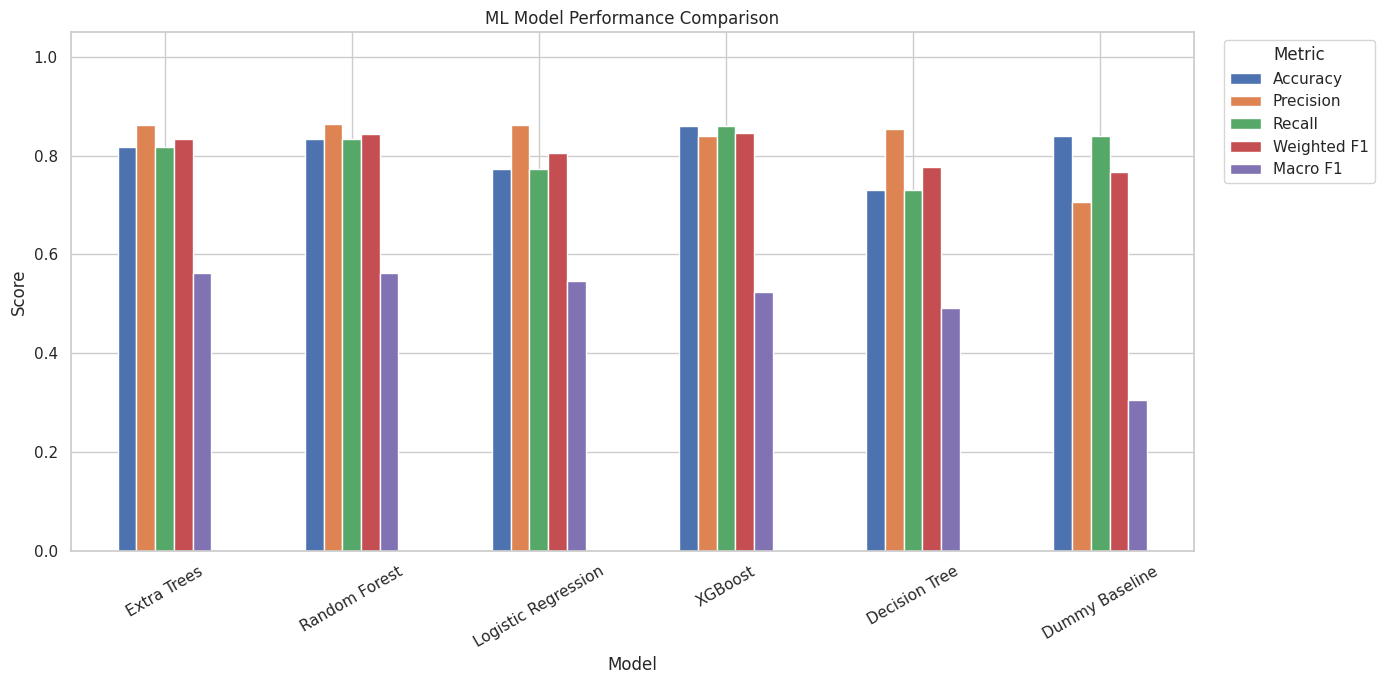


MODEL SELECTION

Selected Model : Extra Trees
Macro F1       : 0.5625

Model selected using Macro F1.

BLOCK 8 COMPLETED SUCCESSFULLY

✓ Baseline model trained
✓ Logistic Regression trained
✓ Decision Tree trained
✓ Random Forest trained
✓ Extra Trees trained
✓ XGBoost trained
✓ Models evaluated on chronological test data
✓ Macro F1 used for model selection
✓ Selected model: Extra Trees

Saved files:
  • inventory_management_models.pkl
  • inventory_management_best_model.pkl
  • inventory_management_label_mapping.pkl

Ready for Block 9 - Detailed Model Evaluation.


In [12]:
# ==========================================================
# Inventory Management
# BLOCK 8 - BASELINE & ML MODEL TRAINING
# ==========================================================

print("=" * 70)
print("BLOCK 8 - MODEL TRAINING & COMPARISON")
print("=" * 70)


# ----------------------------------------------------------
# 1. Prepare model data
# ----------------------------------------------------------

print("\nTraining data shape :", X_train_processed.shape)
print("Testing data shape  :", X_test_processed.shape)

print("\nTarget classes:")
print(y_train.value_counts())


# ----------------------------------------------------------
# 2. Define Evaluation Function
# ----------------------------------------------------------

def evaluate_model(model_name, model, X_test_data, y_test_data):

    predictions = model.predict(X_test_data)

    accuracy = accuracy_score(
        y_test_data,
        predictions
    )

    precision = precision_score(
        y_test_data,
        predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test_data,
        predictions,
        average="weighted",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test_data,
        predictions,
        average="weighted",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test_data,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Weighted F1": weighted_f1,
        "Macro F1": macro_f1
    }


# ----------------------------------------------------------
# 3. Store Results
# ----------------------------------------------------------

model_results = []

trained_models = {}


# ----------------------------------------------------------
# 4. Baseline Model
# ----------------------------------------------------------
#
# DummyClassifier predicts using the most frequent class.
#
# This gives us a benchmark.
# A useful ML model should perform better than this baseline.

print("\n" + "=" * 70)
print("MODEL 1 - DUMMY BASELINE")
print("=" * 70)

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

start_time = time.time()

baseline_model.fit(
    X_train_processed,
    y_train
)

training_time = time.time() - start_time

baseline_result = evaluate_model(
    "Dummy Baseline",
    baseline_model,
    X_test_processed,
    y_test
)

baseline_result["Training Time (sec)"] = training_time

model_results.append(
    baseline_result
)

trained_models["Dummy Baseline"] = baseline_model

print(
    f"Training completed in "
    f"{training_time:.2f} seconds"
)


# ----------------------------------------------------------
# 5. Logistic Regression
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 2 - LOGISTIC REGRESSION")
print("=" * 70)

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

start_time = time.time()

logistic_model.fit(
    X_train_processed,
    y_train
)

training_time = time.time() - start_time

logistic_result = evaluate_model(
    "Logistic Regression",
    logistic_model,
    X_test_processed,
    y_test
)

logistic_result["Training Time (sec)"] = training_time

model_results.append(
    logistic_result
)

trained_models["Logistic Regression"] = logistic_model

print(
    f"Training completed in "
    f"{training_time:.2f} seconds"
)


# ----------------------------------------------------------
# 6. Decision Tree
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 3 - DECISION TREE")
print("=" * 70)

decision_tree_model = DecisionTreeClassifier(
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

start_time = time.time()

decision_tree_model.fit(
    X_train_processed,
    y_train
)

training_time = time.time() - start_time

decision_tree_result = evaluate_model(
    "Decision Tree",
    decision_tree_model,
    X_test_processed,
    y_test
)

decision_tree_result["Training Time (sec)"] = training_time

model_results.append(
    decision_tree_result
)

trained_models["Decision Tree"] = decision_tree_model

print(
    f"Training completed in "
    f"{training_time:.2f} seconds"
)


# ----------------------------------------------------------
# 7. Random Forest
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 4 - RANDOM FOREST")
print("=" * 70)

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=18,
    min_samples_split=10,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_time = time.time()

random_forest_model.fit(
    X_train_processed,
    y_train
)

training_time = time.time() - start_time

random_forest_result = evaluate_model(
    "Random Forest",
    random_forest_model,
    X_test_processed,
    y_test
)

random_forest_result["Training Time (sec)"] = training_time

model_results.append(
    random_forest_result
)

trained_models["Random Forest"] = random_forest_model

print(
    f"Training completed in "
    f"{training_time:.2f} seconds"
)


# ----------------------------------------------------------
# 8. Extra Trees
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 5 - EXTRA TREES")
print("=" * 70)

extra_trees_model = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=18,
    min_samples_split=10,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_time = time.time()

extra_trees_model.fit(
    X_train_processed,
    y_train
)

training_time = time.time() - start_time

extra_trees_result = evaluate_model(
    "Extra Trees",
    extra_trees_model,
    X_test_processed,
    y_test
)

extra_trees_result["Training Time (sec)"] = training_time

model_results.append(
    extra_trees_result
)

trained_models["Extra Trees"] = extra_trees_model

print(
    f"Training completed in "
    f"{training_time:.2f} seconds"
)


# ----------------------------------------------------------
# 9. XGBoost
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 6 - XGBOOST")
print("=" * 70)

# Encode target labels for XGBoost
xgb_label_mapping = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

xgb_reverse_mapping = {
    0: "Low",
    1: "Medium",
    2: "High"
}

y_train_xgb = y_train.map(
    xgb_label_mapping
)

y_test_xgb = y_test.map(
    xgb_label_mapping
)

xgb_model = XGBClassifier(
    n_estimators=250,
    max_depth=6,
    learning_rate=0.08,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_time = time.time()

xgb_model.fit(
    X_train_processed,
    y_train_xgb
)

training_time = time.time() - start_time

xgb_predictions_numeric = xgb_model.predict(
    X_test_processed
)

xgb_predictions = pd.Series(
    xgb_predictions_numeric
).map(
    xgb_reverse_mapping
).values

xgb_accuracy = accuracy_score(
    y_test,
    xgb_predictions
)

xgb_precision = precision_score(
    y_test,
    xgb_predictions,
    average="weighted",
    zero_division=0
)

xgb_recall = recall_score(
    y_test,
    xgb_predictions,
    average="weighted",
    zero_division=0
)

xgb_weighted_f1 = f1_score(
    y_test,
    xgb_predictions,
    average="weighted",
    zero_division=0
)

xgb_macro_f1 = f1_score(
    y_test,
    xgb_predictions,
    average="macro",
    zero_division=0
)

xgb_result = {
    "Model": "XGBoost",
    "Accuracy": xgb_accuracy,
    "Precision": xgb_precision,
    "Recall": xgb_recall,
    "Weighted F1": xgb_weighted_f1,
    "Macro F1": xgb_macro_f1,
    "Training Time (sec)": training_time
}

model_results.append(
    xgb_result
)

trained_models["XGBoost"] = xgb_model

print(
    f"Training completed in "
    f"{training_time:.2f} seconds"
)


# ----------------------------------------------------------
# 10. Model Comparison
# ----------------------------------------------------------

results_df = pd.DataFrame(
    model_results
)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)


print("\n" + "=" * 70)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 70)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Training Time (sec)": "{:.2f}"
    })
)


# ----------------------------------------------------------
# 11. Model Performance Visualization
# ----------------------------------------------------------

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "Weighted F1",
    "Macro F1"
]

plot_df = results_df.set_index("Model")[
    metrics_to_plot
]

plt.figure(figsize=(14, 7))

plot_df.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("ML Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 12. Select Best Model by Macro F1
# ----------------------------------------------------------
#
# Macro F1 gives equal importance to Low, Medium and High
# risk classes, rather than allowing a dominant class to
# hide poor performance on minority classes.

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[
    best_model_name
]

best_macro_f1 = results_df.iloc[0]["Macro F1"]

print("\n" + "=" * 70)
print("MODEL SELECTION")
print("=" * 70)

print(
    f"\nSelected Model : {best_model_name}"
)

print(
    f"Macro F1       : {best_macro_f1:.4f}"
)

print(
    "\nModel selected using Macro F1."
)


# ----------------------------------------------------------
# 13. Save Models
# ----------------------------------------------------------

joblib.dump(
    trained_models,
    "inventory_management_models.pkl"
)

joblib.dump(
    best_model,
    "inventory_management_best_model.pkl"
)

joblib.dump(
    xgb_label_mapping,
    "inventory_management_label_mapping.pkl"
)


# ----------------------------------------------------------
# 14. Final Summary
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("BLOCK 8 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\n✓ Baseline model trained")
print("✓ Logistic Regression trained")
print("✓ Decision Tree trained")
print("✓ Random Forest trained")
print("✓ Extra Trees trained")
print("✓ XGBoost trained")
print("✓ Models evaluated on chronological test data")
print("✓ Macro F1 used for model selection")
print(f"✓ Selected model: {best_model_name}")

print("\nSaved files:")
print("  • inventory_management_models.pkl")
print("  • inventory_management_best_model.pkl")
print("  • inventory_management_label_mapping.pkl")

print("\nReady for Block 9 - Detailed Model Evaluation.")

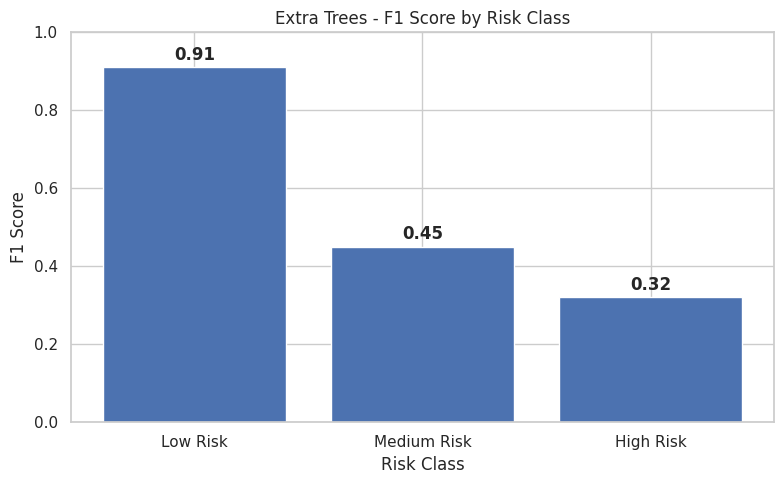

In [13]:
import matplotlib.pyplot as plt

classes = ["Low Risk", "Medium Risk", "High Risk"]
f1_scores = [0.91, 0.45, 0.32]

plt.figure(figsize=(8, 5))

bars = plt.bar(classes, f1_scores)

plt.title("Extra Trees - F1 Score by Risk Class")
plt.xlabel("Risk Class")
plt.ylabel("F1 Score")
plt.ylim(0, 1)

for bar, score in zip(bars, f1_scores):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        score + 0.02,
        f"{score:.2f}",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [19]:

# ----------------------------------------------------------
# 9. Promotion-Level Robustness
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("ROBUSTNESS BY PROMOTION STATUS")
print("=" * 70)

if "Promotion" in robustness_df.columns:

    promotion_robustness = evaluate_subgroup(
        robustness_df,
        "Promotion"
    )

    display(promotion_robustness.round(4))

else:
    promotion_robustness = pd.DataFrame(
        columns=[
            "Promotion",
            "Records",
            "Accuracy",
            "Macro F1",
            "Weighted F1"
        ]
    )

    print(
        "Promotion robustness skipped: "
        "'Promotion' column is not present in the dataset."
    )



ROBUSTNESS BY PROMOTION STATUS
Promotion robustness skipped: 'Promotion' column is not present in the dataset.


BLOCK 10 - FEATURE IMPORTANCE & MODEL EXPLAINABILITY

Selected Model: Extra Trees

TOP 20 MOST IMPORTANT FEATURES


,Feature,Importance
0,numerical__Inventory Level,0.135489
1,numerical__Previous_7D_Average_Inventory,0.079954
2,numerical__Previous_Day_Inventory,0.072097
3,numerical__Inventory_to_Demand,0.069767
4,numerical__Inventory_to_Sales,0.057982
5,numerical__Units Ordered,0.050769
6,numerical__Epidemic,0.025480
7,numerical__Previous_Day_Demand,0.020949
8,numerical__Demand,0.020418
9,numerical__Price,0.020191


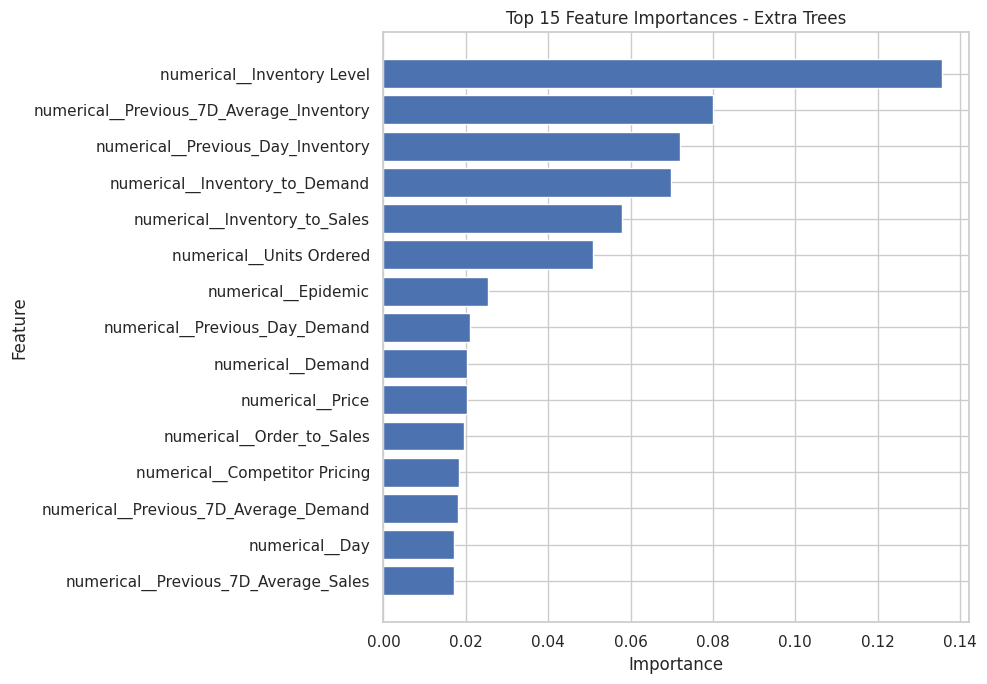


AGGREGATED FEATURE IMPORTANCE


,Original Feature,Total Importance
0,Inventory Level,0.135489
1,Previous_7D_Average_Inventory,0.079954
2,Previous_Day_Inventory,0.072097
3,Inventory_to_Demand,0.069767
4,Inventory_to_Sales,0.057982
5,Region,0.052135
6,Units Ordered,0.050769
7,Category,0.048103
8,Weather Condition,0.041099
9,Seasonality,0.032118


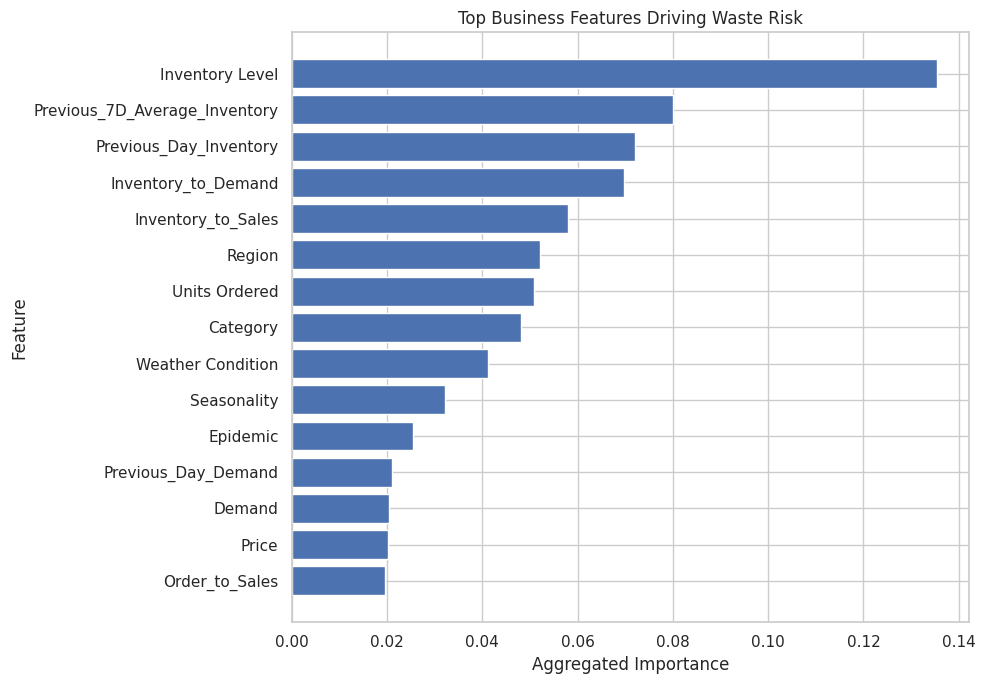


BUSINESS FEATURE IMPORTANCE


,Original Feature,Total Importance
0,Inventory Level,0.135489
1,Previous_7D_Average_Inventory,0.079954
2,Previous_Day_Inventory,0.072097
3,Inventory_to_Demand,0.069767
4,Inventory_to_Sales,0.057982
5,Region,0.052135
6,Units Ordered,0.050769
7,Category,0.048103
8,Weather Condition,0.041099
9,Seasonality,0.032118



TOP BUSINESS DRIVERS
1. Inventory Level → 0.1355
2. Previous_7D_Average_Inventory → 0.0800
3. Previous_Day_Inventory → 0.0721
4. Inventory_to_Demand → 0.0698
5. Inventory_to_Sales → 0.0580
6. Region → 0.0521
7. Units Ordered → 0.0508
8. Category → 0.0481
9. Weather Condition → 0.0411
10. Seasonality → 0.0321

✓ Feature importance files saved.

EXPLAINABILITY SUMMARY

Most influential feature group: Inventory Level

The feature importance values indicate which variables the trained model relied on most when separating waste-risk classes.

Important:
Feature importance shows model reliance, not causation.

BLOCK 10 COMPLETED SUCCESSFULLY

✓ Feature importance calculated
✓ Top model drivers identified
✓ Business-level feature importance aggregated
✓ Explainability outputs saved

Ready for Block 11 - Waste Risk Dashboard & Business Insights.


In [20]:
# ==========================================================
# Inventory Management
# BLOCK 10 - FEATURE IMPORTANCE & MODEL EXPLAINABILITY
# ==========================================================

print("=" * 70)
print("BLOCK 10 - FEATURE IMPORTANCE & MODEL EXPLAINABILITY")
print("=" * 70)


# ----------------------------------------------------------
# 1. Check whether selected model has feature importance
# ----------------------------------------------------------

print(f"\nSelected Model: {best_model_name}")


# ----------------------------------------------------------
# 2. Extract Feature Importance
# ----------------------------------------------------------

feature_importance_df = None

if hasattr(best_model, "feature_importances_"):

    importances = best_model.feature_importances_

    feature_importance_df = pd.DataFrame({
        "Feature": processed_feature_names,
        "Importance": importances
    })

elif hasattr(best_model, "coef_"):

    # Logistic Regression
    coefficients = best_model.coef_

    # For multiclass classification, calculate the
    # average absolute coefficient across classes.
    importances = np.mean(
        np.abs(coefficients),
        axis=0
    )

    feature_importance_df = pd.DataFrame({
        "Feature": processed_feature_names,
        "Importance": importances
    })

else:

    print(
        "\n⚠️ Selected model does not directly expose "
        "feature importance."
    )


# ----------------------------------------------------------
# 3. Sort Feature Importance
# ----------------------------------------------------------

if feature_importance_df is not None:

    feature_importance_df = (
        feature_importance_df
        .sort_values(
            by="Importance",
            ascending=False
        )
        .reset_index(drop=True)
    )

    print("\n" + "=" * 70)
    print("TOP 20 MOST IMPORTANT FEATURES")
    print("=" * 70)

    display(
        feature_importance_df.head(20)
    )


# ----------------------------------------------------------
# 4. Visualize Top 15 Features
# ----------------------------------------------------------

if feature_importance_df is not None:

    top_features = (
        feature_importance_df
        .head(15)
        .sort_values(
            "Importance",
            ascending=True
        )
    )

    plt.figure(figsize=(10, 7))

    plt.barh(
        top_features["Feature"],
        top_features["Importance"]
    )

    plt.title(
        f"Top 15 Feature Importances - "
        f"{best_model_name}"
    )

    plt.xlabel("Importance")
    plt.ylabel("Feature")

    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------
# 5. Aggregate One-Hot Encoded Features
# ----------------------------------------------------------
#
# One categorical variable can produce multiple encoded
# columns. For example:
#
# Region_North
# Region_South
# Region_East
#
# We aggregate them back to their original feature groups
# to make the business interpretation easier.

if feature_importance_df is not None:

    aggregated_importance = {}

    for _, row in feature_importance_df.iterrows():

        feature_name = row["Feature"]
        importance = row["Importance"]

        # Remove ColumnTransformer prefixes
        clean_name = feature_name

        if "__" in clean_name:
            clean_name = clean_name.split(
                "__",
                1
            )[1]

        # Identify original feature
        original_feature = clean_name

        # Handle one-hot encoded categorical variables
        for categorical_feature in categorical_features:

            if clean_name.startswith(
                categorical_feature + "_"
            ):
                original_feature = categorical_feature
                break

        if original_feature not in aggregated_importance:
            aggregated_importance[
                original_feature
            ] = 0

        aggregated_importance[
            original_feature
        ] += importance

    aggregated_importance_df = pd.DataFrame(
        list(
            aggregated_importance.items()
        ),
        columns=[
            "Original Feature",
            "Total Importance"
        ]
    )

    aggregated_importance_df = (
        aggregated_importance_df
        .sort_values(
            "Total Importance",
            ascending=False
        )
        .reset_index(drop=True)
    )

    print("\n" + "=" * 70)
    print("AGGREGATED FEATURE IMPORTANCE")
    print("=" * 70)

    display(
        aggregated_importance_df.head(20)
    )


# ----------------------------------------------------------
# 6. Plot Aggregated Feature Importance
# ----------------------------------------------------------

if feature_importance_df is not None:

    top_aggregated = (
        aggregated_importance_df
        .head(15)
        .sort_values(
            "Total Importance",
            ascending=True
        )
    )

    plt.figure(figsize=(10, 7))

    plt.barh(
        top_aggregated["Original Feature"],
        top_aggregated["Total Importance"]
    )

    plt.title(
        "Top Business Features Driving Waste Risk"
    )

    plt.xlabel("Aggregated Importance")
    plt.ylabel("Feature")

    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------
# 7. Check Business Features
# ----------------------------------------------------------

if feature_importance_df is not None:

    business_features = [
        "Inventory Level",
        "Units Sold",
        "Units Ordered",
        "Demand",
        "Inventory_to_Demand",
        "Inventory_to_Sales",
        "Previous_Day_Sales",
        "Previous_7D_Average_Sales",
        "Previous_7D_Sales",
        "Previous_7D_Average_Demand",
        "Previous_Day_Inventory",
        "Previous_7D_Average_Inventory",
        "Price",
        "Discount",
        "Competitor Pricing",
        "Promotion",
        "Seasonality",
        "Weather Condition",
        "Region",
        "Category"
    ]

    business_importance = (
        aggregated_importance_df[
            aggregated_importance_df[
                "Original Feature"
            ].isin(business_features)
        ]
        .copy()
    )

    print("\n" + "=" * 70)
    print("BUSINESS FEATURE IMPORTANCE")
    print("=" * 70)

    display(
        business_importance
    )


# ----------------------------------------------------------
# 8. Identify Top Business Drivers
# ----------------------------------------------------------

if feature_importance_df is not None:

    top_business_drivers = (
        aggregated_importance_df
        .head(10)
    )

    print("\n" + "=" * 70)
    print("TOP BUSINESS DRIVERS")
    print("=" * 70)

    for i, row in top_business_drivers.iterrows():

        print(
            f"{i + 1}. "
            f"{row['Original Feature']} "
            f"→ "
            f"{row['Total Importance']:.4f}"
        )


# ----------------------------------------------------------
# 9. Save Feature Importance
# ----------------------------------------------------------

if feature_importance_df is not None:

    feature_importance_df.to_csv(
        "inventory_management_feature_importance.csv",
        index=False
    )

    aggregated_importance_df.to_csv(
        "inventory_management_business_feature_importance.csv",
        index=False
    )

    print("\n✓ Feature importance files saved.")


# ----------------------------------------------------------
# 10. Explainability Summary
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("EXPLAINABILITY SUMMARY")
print("=" * 70)

if feature_importance_df is not None:

    top_feature = (
        aggregated_importance_df.iloc[0][
            "Original Feature"
        ]
    )

    print(
        f"\nMost influential feature group: "
        f"{top_feature}"
    )

    print(
        "\nThe feature importance values indicate "
        "which variables the trained model relied on "
        "most when separating waste-risk classes."
    )

    print(
        "\nImportant:"
    )

    print(
        "Feature importance shows model reliance, "
        "not causation."
    )

else:

    print(
        "\nFeature importance is not directly available "
        "for this model."
    )


print("\n" + "=" * 70)
print("BLOCK 10 COMPLETED SUCCESSFULLY")
print("=" * 70)

print(
    "\n✓ Feature importance calculated"
)

print(
    "✓ Top model drivers identified"
)

print(
    "✓ Business-level feature importance aggregated"
)

print(
    "✓ Explainability outputs saved"
)

print(
    "\nReady for Block 11 - Waste Risk Dashboard & Business Insights."
)

BLOCK 11 - Inventory Management DASHBOARD

Dashboard records: 15,060

Inventory Management - KEY PERFORMANCE INDICATORS

Total Inventory Units     : 4,427,009
Average Inventory/Record : 293.96
Total Units Sold         : 1,294,442
Average Demand           : 100.35

High Risk Records        : 658
Medium Risk Records      : 2,870
Low Risk Records         : 11,532
High Risk Percentage     : 4.37%


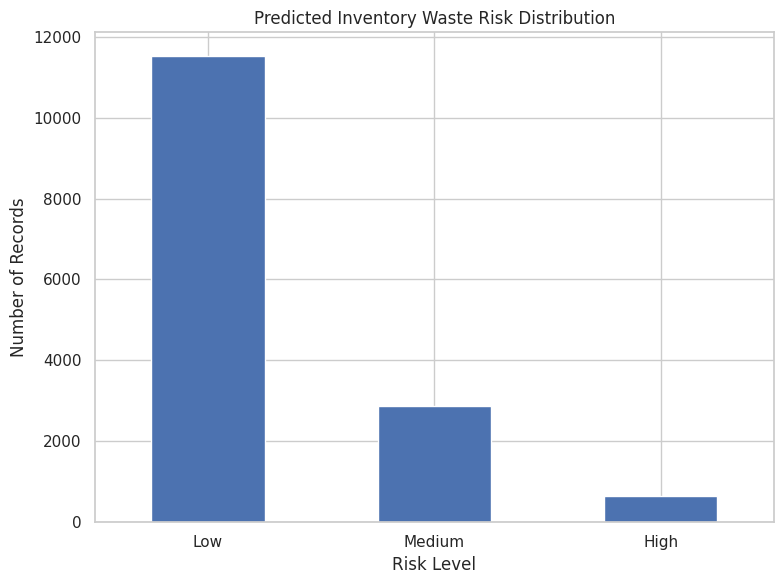


RISK DISTRIBUTION


,Records,Percentage
Predicted Risk,,
Low,11532,76.57
Medium,2870,19.06
High,658,4.37



RISK BY PRODUCT CATEGORY


Predicted Risk,Low,Medium,High,Total,High Risk %
Category,,,,,
Electronics,1418,245,142,1805,7.87
Furniture,1924,602,187,2713,6.89
Clothing,2000,287,124,2411,5.14
Toys,1770,229,107,2106,5.08
Groceries,4420,1507,98,6025,1.63



RISK BY REGION


...

,Total_Records,High_Risk,Average_Inventory,Average_Sales,High Risk %
Store ID,,,,,
S002,3010,221,324.002326,87.696678,7.34
S003,3013,155,314.290076,87.701626,5.14
S001,3012,121,269.495352,84.311421,4.02
S005,3012,85,273.191567,86.456507,2.82
S004,3013,76,288.826087,83.596747,2.52



TOP HIGH-RISK PRODUCTS


,High_Risk_Records,Average_Inventory,Average_Sales,Average_Demand
Product ID,,,,
P0012,85,472.411765,51.105882,57.682353
P0005,81,570.222222,53.098765,60.049383
P0020,56,662.785714,56.285714,63.232143
P0014,56,467.482143,58.232143,63.875000
P0017,52,441.673077,29.865385,33.288462
P0011,43,556.581395,72.209302,77.511628
P0007,43,569.279070,54.674419,65.744186
P0018,39,431.512821,40.974359,46.589744
P0003,38,670.263158,107.815789,115.210526



INVENTORY PROFILE BY PREDICTED RISK


,Average_Inventory,Average_Sales,Average_Demand
Predicted Risk,,,
Low,209.40,89.28,105.49
Medium,573.92,78.08,87.06
High,554.82,61.92,68.25


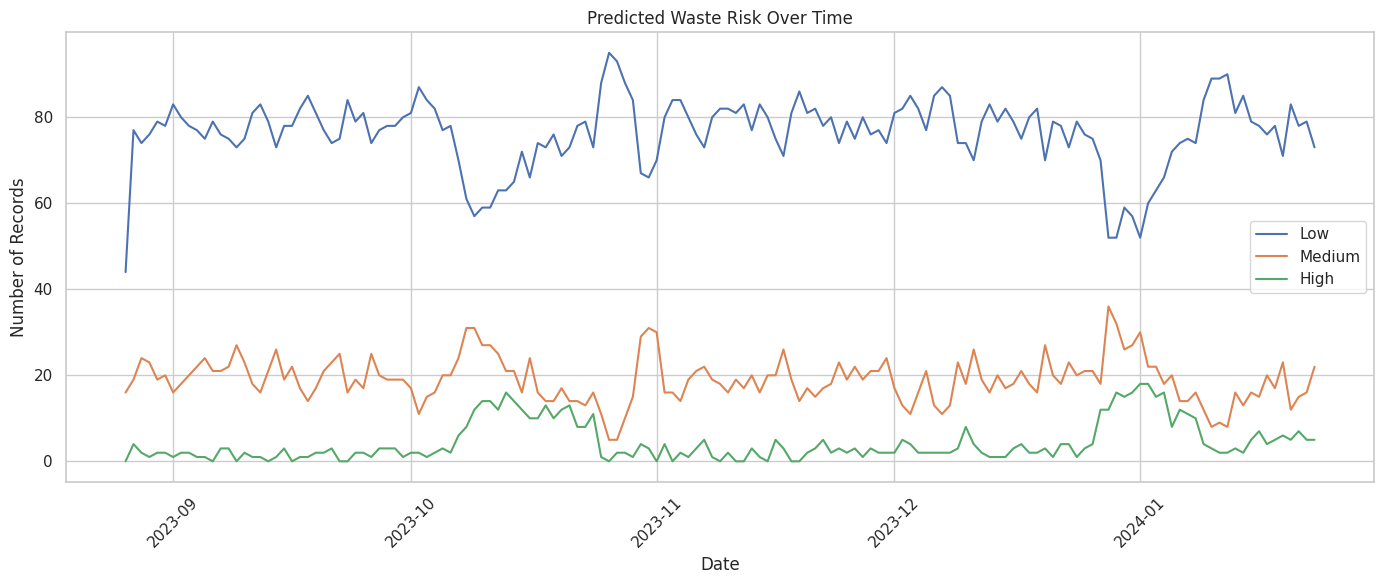


HIGH-RISK INVENTORY TO PRIORITIZE


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Demand,Actual Risk,Predicted Risk,Prediction Confidence
73850,2024-01-09,S003,P0020,Clothing,East,1407.0,53.0,71.0,High,High,0.462553
74718,2024-01-18,S003,P0020,Clothing,East,1397.0,160.0,139.0,Medium,High,0.469141
70628,2023-12-08,S004,P0001,Groceries,West,1366.0,203.0,189.0,High,High,0.515017
73955,2024-01-10,S003,P0020,Clothing,East,1354.0,106.0,109.0,High,High,0.549855
67074,2023-11-02,S003,P0007,Groceries,East,1343.0,179.0,196.0,Medium,High,0.439871
69057,2023-11-22,S002,P0012,Electronics,South,1278.0,110.0,124.0,Medium,High,0.595899
74027,2024-01-11,S003,P0020,Clothing,East,1248.0,176.0,181.0,High,High,0.569490
70393,2023-12-05,S004,P0011,Clothing,West,1238.0,148.0,145.0,Medium,High,0.491898
74866,2024-01-19,S003,P0020,Clothing,East,1237.0,61.0,75.0,Low,High,0.615251
74734,2024-01-18,S003,P0015,Groceries,East,1236.0,154.0,142.0,Medium,High,0.494856



BUSINESS RECOMMENDATIONS

1. INVENTORY MONITORING
Continue monitoring high-risk inventory and prioritize products with repeated High Risk predictions.

2. PRODUCT PRIORITIZATION
Product P0012 has the highest number of High Risk records in the test period. It should be reviewed for inventory reduction or demand stimulation.

3. CATEGORY REVIEW
The category with the highest High Risk percentage is Electronics. Review its ordering and replenishment strategy.

4. REGIONAL INVENTORY REVIEW
The region with the highest High Risk percentage is South. Investigate regional demand patterns and inventory allocation.

5. DATA-DRIVEN REPLENISHMENT
Use historical sales, demand, inventory levels, seasonality, promotions and competitor pricing when planning future inventory orders.

FINAL DASHBOARD SUMMARY


,Metric,Value
0,Total Records,15060
1,Total Inventory,4427009.0
2,Total Units Sold,1294442.0
3,Average Inventory,293.958101
4,Average Demand,100.349137
5,High Risk Records,658
6,Medium Risk Records,2870
7,Low Risk Records,11532
8,High Risk Percentage,4.36919
9,Selected Model,Extra Trees



BLOCK 11 COMPLETED SUCCESSFULLY

✓ Risk dashboard generated
✓ Category risk analysis completed
✓ Region risk analysis completed
✓ Store risk analysis completed
✓ High-risk products identified
✓ Business recommendations generated
✓ Dashboard tables exported

Ready for Block 12 - Final Model Saving & Deployment Pipeline.


In [21]:
# ==========================================================
# Inventory Management
# BLOCK 11 - WASTE RISK DASHBOARD & BUSINESS INSIGHTS
# ==========================================================

print("=" * 70)
print("BLOCK 11 - Inventory Management DASHBOARD")
print("=" * 70)


# ----------------------------------------------------------
# 1. Prepare Dashboard Dataset
# ----------------------------------------------------------

dashboard_df = prediction_analysis.copy()

dashboard_df["Date"] = pd.to_datetime(
    dashboard_df["Date"]
)

print(
    f"\nDashboard records: "
    f"{len(dashboard_df):,}"
)


# ----------------------------------------------------------
# 2. KPI SUMMARY
# ----------------------------------------------------------

total_records = len(dashboard_df)

high_risk_count = (
    dashboard_df["Predicted Risk"]
    .eq("High")
    .sum()
)

medium_risk_count = (
    dashboard_df["Predicted Risk"]
    .eq("Medium")
    .sum()
)

low_risk_count = (
    dashboard_df["Predicted Risk"]
    .eq("Low")
    .sum()
)

high_risk_percentage = (
    high_risk_count
    / total_records
    * 100
)

total_inventory = (
    dashboard_df["Inventory Level"]
    .sum()
)

average_inventory = (
    dashboard_df["Inventory Level"]
    .mean()
)

total_units_sold = (
    dashboard_df["Units Sold"]
    .sum()
)

average_demand = (
    dashboard_df["Demand"]
    .mean()
)


print("\n" + "=" * 70)
print("Inventory Management - KEY PERFORMANCE INDICATORS")
print("=" * 70)

print(
    f"\nTotal Inventory Units     : "
    f"{total_inventory:,.0f}"
)

print(
    f"Average Inventory/Record : "
    f"{average_inventory:,.2f}"
)

print(
    f"Total Units Sold         : "
    f"{total_units_sold:,.0f}"
)

print(
    f"Average Demand           : "
    f"{average_demand:,.2f}"
)

print(
    f"\nHigh Risk Records        : "
    f"{high_risk_count:,}"
)

print(
    f"Medium Risk Records      : "
    f"{medium_risk_count:,}"
)

print(
    f"Low Risk Records         : "
    f"{low_risk_count:,}"
)

print(
    f"High Risk Percentage     : "
    f"{high_risk_percentage:.2f}%"
)


# ----------------------------------------------------------
# 3. Risk Distribution
# ----------------------------------------------------------

risk_counts = (
    dashboard_df["Predicted Risk"]
    .value_counts()
    .reindex(
        ["Low", "Medium", "High"],
        fill_value=0
    )
)

plt.figure(figsize=(8, 6))

risk_counts.plot(
    kind="bar"
)

plt.title(
    "Predicted Inventory Waste Risk Distribution"
)

plt.xlabel("Risk Level")
plt.ylabel("Number of Records")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 4. Risk Distribution Percentage
# ----------------------------------------------------------

risk_percentage_df = (
    risk_counts
    / risk_counts.sum()
    * 100
)

print("\n" + "=" * 70)
print("RISK DISTRIBUTION")
print("=" * 70)

display(
    pd.DataFrame({
        "Records": risk_counts,
        "Percentage": risk_percentage_df.round(2)
    })
)


# ----------------------------------------------------------
# 5. High-Risk Inventory by Category
# ----------------------------------------------------------

category_risk = pd.crosstab(
    dashboard_df["Category"],
    dashboard_df["Predicted Risk"]
)

for risk in ["Low", "Medium", "High"]:

    if risk not in category_risk.columns:
        category_risk[risk] = 0

category_risk = category_risk[
    ["Low", "Medium", "High"]
]

category_risk["Total"] = (
    category_risk[
        ["Low", "Medium", "High"]
    ].sum(axis=1)
)

category_risk["High Risk %"] = (
    category_risk["High"]
    / category_risk["Total"]
    * 100
).round(2)

category_risk = category_risk.sort_values(
    "High Risk %",
    ascending=False
)

print("\n" + "=" * 70)
print("RISK BY PRODUCT CATEGORY")
print("=" * 70)

display(category_risk)


# ----------------------------------------------------------
# 6. High-Risk Inventory by Region
# ----------------------------------------------------------

region_risk = pd.crosstab(
    dashboard_df["Region"],
    dashboard_df["Predicted Risk"]
)

for risk in ["Low", "Medium", "High"]:

    if risk not in region_risk.columns:
        region_risk[risk] = 0

region_risk = region_risk[
    ["Low", "Medium", "High"]
]

region_risk["Total"] = (
    region_risk[
        ["Low", "Medium", "High"]
    ].sum(axis=1)
)

region_risk["High Risk %"] = (
    region_risk["High"]
    / region_risk["Total"]
    * 100
).round(2)

region_risk = region_risk.sort_values(
    "High Risk %",
    ascending=False
)

print("\n" + "=" * 70)
print("RISK BY REGION")
print("=" * 70)

display(region_risk)


# ----------------------------------------------------------
# 7. High-Risk Inventory by Store
# ----------------------------------------------------------

store_risk = (
    dashboard_df
    .groupby("Store ID")
    .agg(
        Total_Records=("Predicted Risk", "size"),
        High_Risk=("Predicted Risk",
                   lambda x: (x == "High").sum()),
        Average_Inventory=("Inventory Level", "mean"),
        Average_Sales=("Units Sold", "mean")
    )
)

store_risk["High Risk %"] = (
    store_risk["High_Risk"]
    / store_risk["Total_Records"]
    * 100
).round(2)

store_risk = store_risk.sort_values(
    "High Risk %",
    ascending=False
)

print("\n" + "=" * 70)
print("STORE-LEVEL RISK ANALYSIS")
print("=" * 70)

display(
    store_risk.head(15)
)


# ----------------------------------------------------------
# 8. High-Risk Products
# ----------------------------------------------------------

high_risk_products = (
    dashboard_df[
        dashboard_df["Predicted Risk"] == "High"
    ]
    .groupby("Product ID")
    .agg(
        High_Risk_Records=("Predicted Risk", "size"),
        Average_Inventory=("Inventory Level", "mean"),
        Average_Sales=("Units Sold", "mean"),
        Average_Demand=("Demand", "mean")
    )
    .sort_values(
        "High_Risk_Records",
        ascending=False
    )
)

print("\n" + "=" * 70)
print("TOP HIGH-RISK PRODUCTS")
print("=" * 70)

display(
    high_risk_products.head(15)
)


# ----------------------------------------------------------
# 9. Inventory vs Sales for Predicted Risk
# ----------------------------------------------------------

risk_inventory_summary = (
    dashboard_df
    .groupby("Predicted Risk")
    .agg(
        Average_Inventory=("Inventory Level", "mean"),
        Average_Sales=("Units Sold", "mean"),
        Average_Demand=("Demand", "mean")
    )
    .reindex(
        ["Low", "Medium", "High"]
    )
)

print("\n" + "=" * 70)
print("INVENTORY PROFILE BY PREDICTED RISK")
print("=" * 70)

display(
    risk_inventory_summary.round(2)
)


# ----------------------------------------------------------
# 10. Risk Over Time
# ----------------------------------------------------------

daily_risk = pd.crosstab(
    dashboard_df["Date"],
    dashboard_df["Predicted Risk"]
)

for risk in ["Low", "Medium", "High"]:

    if risk not in daily_risk.columns:
        daily_risk[risk] = 0

daily_risk = daily_risk[
    ["Low", "Medium", "High"]
]

plt.figure(figsize=(14, 6))

plt.plot(
    daily_risk.index,
    daily_risk["Low"],
    label="Low"
)

plt.plot(
    daily_risk.index,
    daily_risk["Medium"],
    label="Medium"
)

plt.plot(
    daily_risk.index,
    daily_risk["High"],
    label="High"
)

plt.title(
    "Predicted Waste Risk Over Time"
)

plt.xlabel("Date")
plt.ylabel("Number of Records")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 11. High-Risk Inventory Table
# ----------------------------------------------------------

high_risk_inventory = (
    dashboard_df[
        dashboard_df["Predicted Risk"] == "High"
    ]
    .sort_values(
        "Inventory Level",
        ascending=False
    )
)

high_risk_columns = [
    "Date",
    "Store ID",
    "Product ID",
    "Category",
    "Region",
    "Inventory Level",
    "Units Sold",
    "Demand",
    "Actual Risk",
    "Predicted Risk"
]

if "Prediction Confidence" in high_risk_inventory.columns:

    high_risk_columns.append(
        "Prediction Confidence"
    )

print("\n" + "=" * 70)
print("HIGH-RISK INVENTORY TO PRIORITIZE")
print("=" * 70)

display(
    high_risk_inventory[
        high_risk_columns
    ].head(25)
)


# ----------------------------------------------------------
# 12. Generate Business Recommendations
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("BUSINESS RECOMMENDATIONS")
print("=" * 70)


# Recommendation 1
if high_risk_percentage > 30:

    print(
        "\n1. INVENTORY REDUCTION"
    )

    print(
        "A relatively large proportion of records "
        "are classified as High Risk. Review excess "
        "inventory and consider reducing future orders."
    )

else:

    print(
        "\n1. INVENTORY MONITORING"
    )

    print(
        "Continue monitoring high-risk inventory and "
        "prioritize products with repeated High Risk predictions."
    )


# Recommendation 2
if len(high_risk_products) > 0:

    top_product = (
        high_risk_products.index[0]
    )

    print(
        "\n2. PRODUCT PRIORITIZATION"
    )

    print(
        f"Product {top_product} has the highest number "
        "of High Risk records in the test period. "
        "It should be reviewed for inventory reduction "
        "or demand stimulation."
    )


# Recommendation 3
if len(category_risk) > 0:

    top_category = (
        category_risk.index[0]
    )

    print(
        "\n3. CATEGORY REVIEW"
    )

    print(
        f"The category with the highest High Risk "
        f"percentage is {top_category}. "
        "Review its ordering and replenishment strategy."
    )


# Recommendation 4
if len(region_risk) > 0:

    top_region = (
        region_risk.index[0]
    )

    print(
        "\n4. REGIONAL INVENTORY REVIEW"
    )

    print(
        f"The region with the highest High Risk "
        f"percentage is {top_region}. "
        "Investigate regional demand patterns and "
        "inventory allocation."
    )


# Recommendation 5

print(
    "\n5. DATA-DRIVEN REPLENISHMENT"
)

print(
    "Use historical sales, demand, inventory levels, "
    "seasonality, promotions and competitor pricing "
    "when planning future inventory orders."
)


# ----------------------------------------------------------
# 13. Export Dashboard Tables
# ----------------------------------------------------------

risk_counts.to_csv(
    "inventory_management_risk_distribution.csv"
)

category_risk.to_csv(
    "inventory_management_category_risk.csv"
)

region_risk.to_csv(
    "inventory_management_region_risk.csv"
)

store_risk.to_csv(
    "inventory_management_store_risk.csv"
)

high_risk_products.to_csv(
    "inventory_management_high_risk_products.csv"
)

high_risk_inventory[
    high_risk_columns
].to_csv(
    "inventory_management_high_risk_inventory.csv",
    index=False
)


# ----------------------------------------------------------
# 14. Dashboard Summary Object
# ----------------------------------------------------------

dashboard_summary = {
    "Total Records": total_records,
    "Total Inventory": total_inventory,
    "Total Units Sold": total_units_sold,
    "Average Inventory": average_inventory,
    "Average Demand": average_demand,
    "High Risk Records": high_risk_count,
    "Medium Risk Records": medium_risk_count,
    "Low Risk Records": low_risk_count,
    "High Risk Percentage": high_risk_percentage,
    "Selected Model": best_model_name,
    "Model Accuracy": final_accuracy,
    "Model Macro F1": final_macro_f1,
    "Model Weighted F1": final_weighted_f1
}

dashboard_summary_df = pd.DataFrame(
    dashboard_summary.items(),
    columns=["Metric", "Value"]
)

print("\n" + "=" * 70)
print("FINAL DASHBOARD SUMMARY")
print("=" * 70)

display(
    dashboard_summary_df
)


print("\n" + "=" * 70)
print("BLOCK 11 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\n✓ Risk dashboard generated")
print("✓ Category risk analysis completed")
print("✓ Region risk analysis completed")
print("✓ Store risk analysis completed")
print("✓ High-risk products identified")
print("✓ Business recommendations generated")
print("✓ Dashboard tables exported")

print(
    "\nReady for Block 12 - Final Model Saving & Deployment Pipeline."
)

In [22]:
# ==========================================================
# Inventory Management
# BLOCK 12 - FINAL MODEL PIPELINE & DEPLOYMENT
# ==========================================================

print("=" * 70)
print("BLOCK 12 - FINAL MODEL PIPELINE & DEPLOYMENT")
print("=" * 70)


# ----------------------------------------------------------
# 1. Display Selected Model
# ----------------------------------------------------------

print("\nSelected Model:")
print(best_model_name)

print("\nModel Performance:")
print(f"Accuracy    : {final_accuracy:.4f}")
print(f"Macro F1    : {final_macro_f1:.4f}")
print(f"Weighted F1 : {final_weighted_f1:.4f}")


# ----------------------------------------------------------
# 2. Create Complete Prediction Pipeline
# ----------------------------------------------------------
#
# The pipeline combines:
#
# Raw Data
#     ↓
# Preprocessing
#     ↓
# Trained ML Model
#     ↓
# Waste Risk Prediction
#
# This makes it easier to use the model on new data.

final_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor
        ),
        (
            "model",
            best_model
        )
    ]
)


# ----------------------------------------------------------
# 3. Verify Complete Pipeline
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("PIPELINE VERIFICATION")
print("=" * 70)

print("\nPipeline components:")

for name, component in final_pipeline.steps:

    print(
        f"✓ {name}: "
        f"{type(component).__name__}"
    )


# ----------------------------------------------------------
# 4. Test Complete Pipeline
# ----------------------------------------------------------
#
# We use the original X_test dataframe here rather than
# X_test_processed because the pipeline performs the
# preprocessing itself.

pipeline_predictions = final_pipeline.predict(
    X_test
)

pipeline_accuracy = accuracy_score(
    y_test,
    pipeline_predictions
)

pipeline_macro_f1 = f1_score(
    y_test,
    pipeline_predictions,
    average="macro",
    zero_division=0
)

print("\nPipeline Test Results:")

print(
    f"Accuracy : {pipeline_accuracy:.4f}"
)

print(
    f"Macro F1 : {pipeline_macro_f1:.4f}"
)


# ----------------------------------------------------------
# 5. Verify Pipeline Matches Previous Model
# ----------------------------------------------------------

predictions_match = np.array_equal(
    best_predictions,
    pipeline_predictions
)

print("\nPrediction consistency check:")

if predictions_match:

    print(
        "✓ Complete pipeline produces the "
        "same predictions as the trained model."
    )

else:

    print(
        "⚠️ Pipeline predictions differ. "
        "Check preprocessing configuration."
    )


# ----------------------------------------------------------
# 6. Save Complete Pipeline
# ----------------------------------------------------------

joblib.dump(
    final_pipeline,
    "inventory_management_ai_pipeline.pkl"
)

print(
    "\n✓ Complete pipeline saved as:"
)

print(
    "  inventory_management_ai_pipeline.pkl"
)


# ----------------------------------------------------------
# 7. Save Feature Configuration
# ----------------------------------------------------------

feature_configuration = {
    "target": TARGET,
    "model_features": MODEL_FEATURES,
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "risk_classes": [
        "Low",
        "Medium",
        "High"
    ],
    "selected_model": best_model_name
}

joblib.dump(
    feature_configuration,
    "inventory_management_feature_configuration.pkl"
)

print(
    "\n✓ Feature configuration saved."
)


# ----------------------------------------------------------
# 8. Create a Reusable Prediction Function
# ----------------------------------------------------------

def predict_waste_risk(new_data):
    """
    Predict future inventory waste risk
    for new inventory records.

    Parameters
    ----------
    new_data : pandas.DataFrame
        DataFrame containing the same model input
        features used during training.

    Returns
    -------
    pandas.DataFrame
        Original records with predicted risk.
    """

    required_columns = MODEL_FEATURES

    missing_columns = [
        column
        for column in required_columns
        if column not in new_data.columns
    ]

    if missing_columns:

        raise ValueError(
            "Missing required columns: "
            + str(missing_columns)
        )

    prediction_data = new_data[
        required_columns
    ].copy()

    predictions = final_pipeline.predict(
        prediction_data
    )

    result = new_data.copy()

    result["Predicted Waste Risk"] = predictions

    # Add prediction probability if supported
    if hasattr(
        final_pipeline.named_steps["model"],
        "predict_proba"
    ):

        probabilities = (
            final_pipeline.predict_proba(
                prediction_data
            )
        )

        result[
            "Prediction Confidence"
        ] = probabilities.max(axis=1)

    return result


# ----------------------------------------------------------
# 9. Test Reusable Prediction Function
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("TESTING REUSABLE PREDICTION FUNCTION")
print("=" * 70)

sample_new_data = X_test.head(10).copy()

sample_predictions = predict_waste_risk(
    sample_new_data
)

display(
    sample_predictions[
        MODEL_FEATURES[:5]
        + ["Predicted Waste Risk"]
        + (
            ["Prediction Confidence"]
            if "Prediction Confidence"
            in sample_predictions.columns
            else []
        )
    ]
)


# ----------------------------------------------------------
# 10. Save Sample Predictions
# ----------------------------------------------------------

sample_predictions.to_csv(
    "inventory_management_sample_predictions.csv",
    index=False
)

print(
    "\n✓ Sample predictions saved."
)


# ----------------------------------------------------------
# 11. Create Model Metadata
# ----------------------------------------------------------

model_metadata = {
    "Project": "Inventory Management",
    "Problem": "Future 7-Day Inventory Waste Risk Prediction",
    "Target": "Waste Risk",
    "Classes": ["Low", "Medium", "High"],
    "Selected Model": best_model_name,
    "Accuracy": float(final_accuracy),
    "Macro F1": float(final_macro_f1),
    "Weighted F1": float(final_weighted_f1),
    "Training Records": int(len(X_train)),
    "Testing Records": int(len(X_test)),
    "Number of Model Features": int(len(MODEL_FEATURES)),
    "Numerical Features": int(len(numerical_features)),
    "Categorical Features": int(len(categorical_features))
}

model_metadata_df = pd.DataFrame(
    model_metadata.items(),
    columns=["Property", "Value"]
)

print("\n" + "=" * 70)
print("MODEL METADATA")
print("=" * 70)

display(
    model_metadata_df
)


# ----------------------------------------------------------
# 12. Save Metadata
# ----------------------------------------------------------

model_metadata_df.to_csv(
    "inventory_management_model_metadata.csv",
    index=False
)


# ----------------------------------------------------------
# 13. Final Project File Summary
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("GENERATED PROJECT FILES")
print("=" * 70)

project_files = [
    "inventory_management_preprocessor.pkl",
    "inventory_management_models.pkl",
    "inventory_management_best_model.pkl",
    "inventory_management_label_mapping.pkl",
    "inventory_management_ai_pipeline.pkl",
    "inventory_management_feature_configuration.pkl",
    "inventory_management_predictions.csv",
    "inventory_management_classification_report.csv",
    "inventory_management_feature_importance.csv",
    "inventory_management_business_feature_importance.csv",
    "inventory_management_risk_distribution.csv",
    "inventory_management_category_risk.csv",
    "inventory_management_region_risk.csv",
    "inventory_management_store_risk.csv",
    "inventory_management_high_risk_products.csv",
    "inventory_management_high_risk_inventory.csv",
    "inventory_management_sample_predictions.csv",
    "inventory_management_model_metadata.csv"
]

for file_name in project_files:

    if os.path.exists(file_name):

        print(
            f"✓ {file_name}"
        )

    else:

        print(
            f"⚠️ Not found: {file_name}"
        )


print("\n" + "=" * 70)
print("BLOCK 12 COMPLETED SUCCESSFULLY")
print("=" * 70)

print(
    "\n✓ Complete preprocessing + model pipeline created"
)

print(
    "✓ Pipeline tested on unseen test data"
)

print(
    "✓ Reusable prediction function created"
)

print(
    "✓ Model configuration saved"
)

print(
    "✓ Model metadata saved"
)

print(
    "\nInventory Management ML pipeline is now deployment-ready."
)

BLOCK 12 - FINAL MODEL PIPELINE & DEPLOYMENT

Selected Model:
Extra Trees

Model Performance:
Accuracy    : 0.8174
Macro F1    : 0.5625
Weighted F1 : 0.8345

PIPELINE VERIFICATION

Pipeline components:
✓ preprocessing: ColumnTransformer
✓ model: ExtraTreesClassifier

Pipeline Test Results:
Accuracy : 0.8174
Macro F1 : 0.5625

Prediction consistency check:
✓ Complete pipeline produces the same predictions as the trained model.

✓ Complete pipeline saved as:
  inventory_management_ai_pipeline.pkl

✓ Feature configuration saved.

TESTING REUSABLE PREDICTION FUNCTION


,Inventory Level,Units Sold,Units Ordered,Price,Discount,Predicted Waste Risk,Prediction Confidence
60240,827.0,123.0,0.0,84.81,10,Medium,0.423490
60241,491.0,130.0,0.0,81.83,10,Low,0.458872
60242,170.0,66.0,0.0,25.13,5,Low,0.910322
60243,422.0,43.0,0.0,108.18,5,Medium,0.476638
60244,560.0,43.0,0.0,61.51,0,Medium,0.447687
60245,1071.0,104.0,0.0,22.41,10,Medium,0.590522
60246,159.0,106.0,98.0,87.77,5,Low,0.961192
60247,217.0,57.0,0.0,114.06,10,Low,0.613935
60248,169.0,64.0,70.0,76.43,10,Low,0.924435
60249,125.0,125.0,930.0,70.42,15,Low,0.914464



✓ Sample predictions saved.

MODEL METADATA


,Property,Value
0,Project,Inventory Management
1,Problem,Future 7-Day Inventory Waste Risk Prediction
2,Target,Waste Risk
3,Classes,"[Low, Medium, High]"
4,Selected Model,Extra Trees
5,Accuracy,0.817397
6,Macro F1,0.562486
7,Weighted F1,0.834477
8,Training Records,60240
9,Testing Records,15060



GENERATED PROJECT FILES
✓ inventory_management_preprocessor.pkl
✓ inventory_management_models.pkl
✓ inventory_management_best_model.pkl
✓ inventory_management_label_mapping.pkl
✓ inventory_management_ai_pipeline.pkl
✓ inventory_management_feature_configuration.pkl
✓ inventory_management_predictions.csv
✓ inventory_management_classification_report.csv
✓ inventory_management_feature_importance.csv
✓ inventory_management_business_feature_importance.csv
✓ inventory_management_risk_distribution.csv
✓ inventory_management_category_risk.csv
✓ inventory_management_region_risk.csv
✓ inventory_management_store_risk.csv
✓ inventory_management_high_risk_products.csv
✓ inventory_management_high_risk_inventory.csv
✓ inventory_management_sample_predictions.csv
✓ inventory_management_model_metadata.csv

BLOCK 12 COMPLETED SUCCESSFULLY

✓ Complete preprocessing + model pipeline created
✓ Pipeline tested on unseen test data
✓ Reusable prediction function created
✓ Model configuration saved
✓ Model meta

BLOCK 13 - ABLATION STUDY

Baseline feature count   : 13
Engineered feature count : 18

Training baseline Random Forest...

ABLATION STUDY RESULTS


,Experiment,Accuracy,Precision,Recall,Weighted F1,Macro F1
0,Baseline Features,0.8237,0.8598,0.8237,0.8382,0.5670
1,Full Feature Set,0.8341,0.8637,0.8341,0.8435,0.5622



FEATURE ENGINEERING IMPACT

Macro F1 improvement : -0.0048
Accuracy improvement : +0.0104


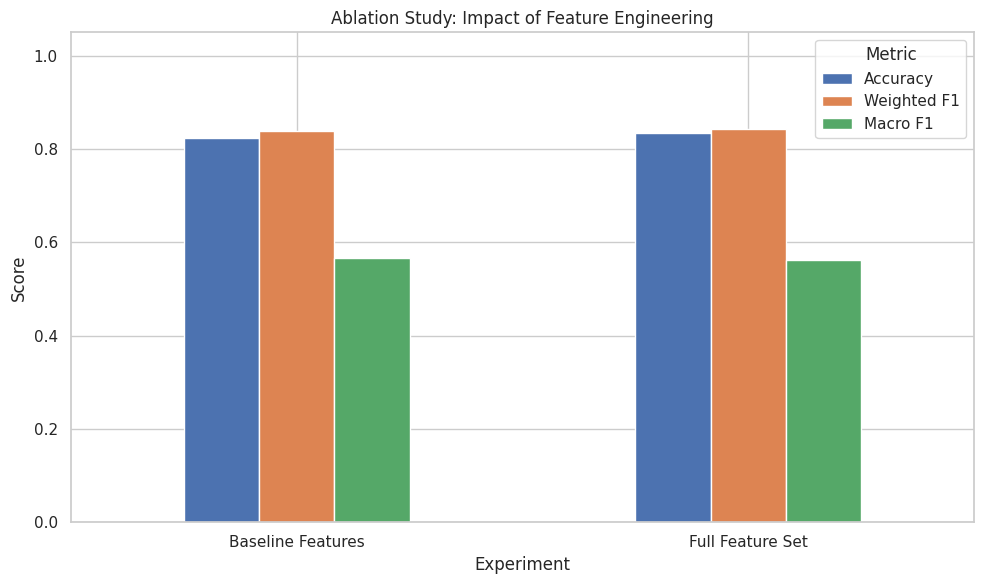


CONTROLLED EXPERIMENT CONCLUSION

The baseline feature set achieved a higher Macro F1 than the full feature set.
This indicates that the additional engineered features did not improve this controlled experiment and should be investigated further.

BLOCK 13 COMPLETED SUCCESSFULLY

✓ Controlled experiment completed
✓ Baseline vs engineered features compared
✓ Same chronological split maintained
✓ Same Random Forest configuration used
✓ Feature engineering impact measured

Saved:
  • inventory_management_ablation_results.csv
  • inventory_management_ablation_preprocessor.pkl
  • inventory_management_ablation_model.pkl

Ready for Block 14 - Robustness & Subgroup Testing.


In [23]:
# ==========================================================
# Inventory Management
# BLOCK 13 - ABLATION / CONTROLLED EXPERIMENT
# ==========================================================

print("=" * 70)
print("BLOCK 13 - ABLATION STUDY")
print("=" * 70)


# ----------------------------------------------------------
# 1. Define Feature Groups
# ----------------------------------------------------------

# Original/current business variables
baseline_features = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Epidemic",
    "Demand",
    "Category",
    "Region",
    "Weather Condition",
    "Promotion",
    "Seasonality"
]

# Engineered historical and ratio features
engineered_features_ablation = [
    "Day",
    "DayOfWeek",
    "Month",
    "Quarter",
    "WeekOfYear",
    "IsWeekend",
    "Inventory_to_Demand",
    "Inventory_to_Sales",
    "Order_to_Sales",
    "Price_Gap",
    "Previous_Day_Sales",
    "Previous_7D_Average_Sales",
    "Previous_7D_Max_Sales",
    "Previous_7D_Sales",
    "Previous_Day_Demand",
    "Previous_7D_Average_Demand",
    "Previous_Day_Inventory",
    "Previous_7D_Average_Inventory"
]


print("\nBaseline feature count   :", len(baseline_features))
print("Engineered feature count :", len(engineered_features_ablation))


# ----------------------------------------------------------
# 2. Create Baseline Feature Dataset
# ----------------------------------------------------------

X_baseline = ml_df[
    baseline_features
].copy()

y_ablation = ml_df[
    TARGET
].copy()


# ----------------------------------------------------------
# 3. Use SAME chronological split
# ----------------------------------------------------------

ablation_split = int(
    len(ml_df) * 0.80
)

X_baseline_train = X_baseline.iloc[
    :ablation_split
].copy()

X_baseline_test = X_baseline.iloc[
    ablation_split:
].copy()

y_baseline_train = y_ablation.iloc[
    :ablation_split
].copy()

y_baseline_test = y_ablation.iloc[
    ablation_split:
].copy()


# ----------------------------------------------------------
# 4. Identify Feature Types
# ----------------------------------------------------------

baseline_categorical = X_baseline_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

baseline_numerical = X_baseline_train.select_dtypes(
    include=np.number
).columns.tolist()


# ----------------------------------------------------------
# 5. Create Baseline Preprocessor
# ----------------------------------------------------------

baseline_numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

baseline_categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

baseline_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            baseline_numerical_pipeline,
            baseline_numerical
        ),
        (
            "categorical",
            baseline_categorical_pipeline,
            baseline_categorical
        )
    ]
)


# ----------------------------------------------------------
# 6. Transform Baseline Data
# ----------------------------------------------------------

X_baseline_train_processed = (
    baseline_preprocessor.fit_transform(
        X_baseline_train
    )
)

X_baseline_test_processed = (
    baseline_preprocessor.transform(
        X_baseline_test
    )
)


# ----------------------------------------------------------
# 7. Train Controlled Model
# ----------------------------------------------------------
#
# We use Random Forest because it is already one of the
# models tested in the main experiment.
#
# Same model family + same split = controlled comparison.

ablation_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=18,
    min_samples_split=10,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("\nTraining baseline Random Forest...")

ablation_model.fit(
    X_baseline_train_processed,
    y_baseline_train
)

ablation_predictions = (
    ablation_model.predict(
        X_baseline_test_processed
    )
)


# ----------------------------------------------------------
# 8. Evaluate Ablation Model
# ----------------------------------------------------------

ablation_accuracy = accuracy_score(
    y_baseline_test,
    ablation_predictions
)

ablation_precision = precision_score(
    y_baseline_test,
    ablation_predictions,
    average="weighted",
    zero_division=0
)

ablation_recall = recall_score(
    y_baseline_test,
    ablation_predictions,
    average="weighted",
    zero_division=0
)

ablation_weighted_f1 = f1_score(
    y_baseline_test,
    ablation_predictions,
    average="weighted",
    zero_division=0
)

ablation_macro_f1 = f1_score(
    y_baseline_test,
    ablation_predictions,
    average="macro",
    zero_division=0
)


# ----------------------------------------------------------
# 9. Full Model Performance
# ----------------------------------------------------------

# The main experiment's Random Forest result
# is retrieved from the model comparison table.

full_rf_row = results_df[
    results_df["Model"] == "Random Forest"
]

if len(full_rf_row) > 0:

    full_accuracy = float(
        full_rf_row.iloc[0]["Accuracy"]
    )

    full_precision = float(
        full_rf_row.iloc[0]["Precision"]
    )

    full_recall = float(
        full_rf_row.iloc[0]["Recall"]
    )

    full_weighted_f1 = float(
        full_rf_row.iloc[0]["Weighted F1"]
    )

    full_macro_f1 = float(
        full_rf_row.iloc[0]["Macro F1"]
    )

else:

    # Fallback: evaluate the full Random Forest directly

    full_rf_predictions = random_forest_model.predict(
        X_test_processed
    )

    full_accuracy = accuracy_score(
        y_test,
        full_rf_predictions
    )

    full_precision = precision_score(
        y_test,
        full_rf_predictions,
        average="weighted",
        zero_division=0
    )

    full_recall = recall_score(
        y_test,
        full_rf_predictions,
        average="weighted",
        zero_division=0
    )

    full_weighted_f1 = f1_score(
        y_test,
        full_rf_predictions,
        average="weighted",
        zero_division=0
    )

    full_macro_f1 = f1_score(
        y_test,
        full_rf_predictions,
        average="macro",
        zero_division=0
    )


# ----------------------------------------------------------
# 10. Ablation Comparison
# ----------------------------------------------------------

ablation_results = pd.DataFrame({

    "Experiment": [
        "Baseline Features",
        "Full Feature Set"
    ],

    "Accuracy": [
        ablation_accuracy,
        full_accuracy
    ],

    "Precision": [
        ablation_precision,
        full_precision
    ],

    "Recall": [
        ablation_recall,
        full_recall
    ],

    "Weighted F1": [
        ablation_weighted_f1,
        full_weighted_f1
    ],

    "Macro F1": [
        ablation_macro_f1,
        full_macro_f1
    ]
})


print("\n" + "=" * 70)
print("ABLATION STUDY RESULTS")
print("=" * 70)

display(
    ablation_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Macro F1": "{:.4f}"
    })
)


# ----------------------------------------------------------
# 11. Calculate Improvement
# ----------------------------------------------------------

macro_f1_improvement = (
    full_macro_f1
    - ablation_macro_f1
)

accuracy_improvement = (
    full_accuracy
    - ablation_accuracy
)

print("\n" + "=" * 70)
print("FEATURE ENGINEERING IMPACT")
print("=" * 70)

print(
    f"\nMacro F1 improvement : "
    f"{macro_f1_improvement:+.4f}"
)

print(
    f"Accuracy improvement : "
    f"{accuracy_improvement:+.4f}"
)


# ----------------------------------------------------------
# 12. Visualize Ablation Results
# ----------------------------------------------------------

ablation_plot = ablation_results.set_index(
    "Experiment"
)[
    [
        "Accuracy",
        "Weighted F1",
        "Macro F1"
    ]
]

ablation_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Ablation Study: Impact of Feature Engineering"
)

plt.xlabel("Experiment")
plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.legend(
    title="Metric"
)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 13. Controlled Experiment Conclusion
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("CONTROLLED EXPERIMENT CONCLUSION")
print("=" * 70)

if macro_f1_improvement > 0:

    print(
        "\n✓ The full feature set achieved a higher "
        "Macro F1 than the baseline feature set."
    )

    print(
        "This provides evidence that the engineered "
        "historical, calendar and inventory-ratio "
        "features add predictive information."
    )

elif macro_f1_improvement < 0:

    print(
        "\nThe baseline feature set achieved a higher "
        "Macro F1 than the full feature set."
    )

    print(
        "This indicates that the additional engineered "
        "features did not improve this controlled "
        "experiment and should be investigated further."
    )

else:

    print(
        "\nThe two feature configurations achieved "
        "the same Macro F1."
    )

    print(
        "The engineered features did not produce a "
        "measurable improvement in this experiment."
    )


# ----------------------------------------------------------
# 14. Save Ablation Results
# ----------------------------------------------------------

ablation_results.to_csv(
    "inventory_management_ablation_results.csv",
    index=False
)

joblib.dump(
    baseline_preprocessor,
    "inventory_management_ablation_preprocessor.pkl"
)

joblib.dump(
    ablation_model,
    "inventory_management_ablation_model.pkl"
)


print("\n" + "=" * 70)
print("BLOCK 13 COMPLETED SUCCESSFULLY")
print("=" * 70)

print(
    "\n✓ Controlled experiment completed"
)

print(
    "✓ Baseline vs engineered features compared"
)

print(
    "✓ Same chronological split maintained"
)

print(
    "✓ Same Random Forest configuration used"
)

print(
    "✓ Feature engineering impact measured"
)

print(
    "\nSaved:"
)

print(
    "  • inventory_management_ablation_results.csv"
)

print(
    "  • inventory_management_ablation_preprocessor.pkl"
)

print(
    "  • inventory_management_ablation_model.pkl"
)

print(
    "\nReady for Block 14 - Robustness & Subgroup Testing."
)

BLOCK 14 - ROBUSTNESS & SUBGROUP TESTING

Evaluation records: 15,060

OVERALL TEST PERFORMANCE

Accuracy    : 0.8174
Macro F1    : 0.5625
Weighted F1 : 0.8345

ROBUSTNESS BY CATEGORY


,Category,Records,Accuracy,Macro F1,Weighted F1
0,Toys,2106,0.8623,0.5943,0.8711
1,Furniture,2713,0.7822,0.5920,0.8002
2,Electronics,1805,0.8216,0.5356,0.8387
3,Clothing,2411,0.8611,0.5317,0.8740
4,Groceries,6025,0.7988,0.5225,0.8170



ROBUSTNESS BY REGION


,Region,Records,Accuracy,Macro F1,Weighted F1
0,East,3013,0.8128,0.5879,0.8273
1,North,6024,0.8456,0.5731,0.8592
2,South,3010,0.7641,0.5392,0.7905
3,West,3013,0.8188,0.5258,0.8352



ROBUSTNESS BY STORE


...

,Inventory Group,Records,Accuracy,Macro F1,Weighted F1
0,High Inventory,5008,0.5687,0.5023,0.5912
1,Medium Inventory,5032,0.8994,0.4976,0.8981
2,Low Inventory,5020,0.9833,0.3570,0.9780



ROBUSTNESS BY DEMAND LEVEL


,Demand Group,Records,Accuracy,Macro F1,Weighted F1
0,Low Demand,5065,0.7356,0.5583,0.7619
1,High Demand,4945,0.8918,0.5471,0.9001
2,Medium Demand,5050,0.8265,0.5294,0.8406



ROBUSTNESS BY PROMOTION STATUS
Promotion robustness skipped: 'Promotion' column is not available.

SUBGROUP ROBUSTNESS SUMMARY


,Subgroup,Number of Groups,Average Accuracy,Average Macro F1,Minimum Macro F1,Maximum Macro F1
0,Category,5,0.8252,0.5552,0.5225,0.5943
1,Region,4,0.8103,0.5565,0.5258,0.5879
2,Store,5,0.8174,0.5603,0.5258,0.5879
3,Inventory Level,3,0.8171,0.4523,0.3570,0.5023
4,Demand Level,3,0.8180,0.5449,0.5294,0.5583


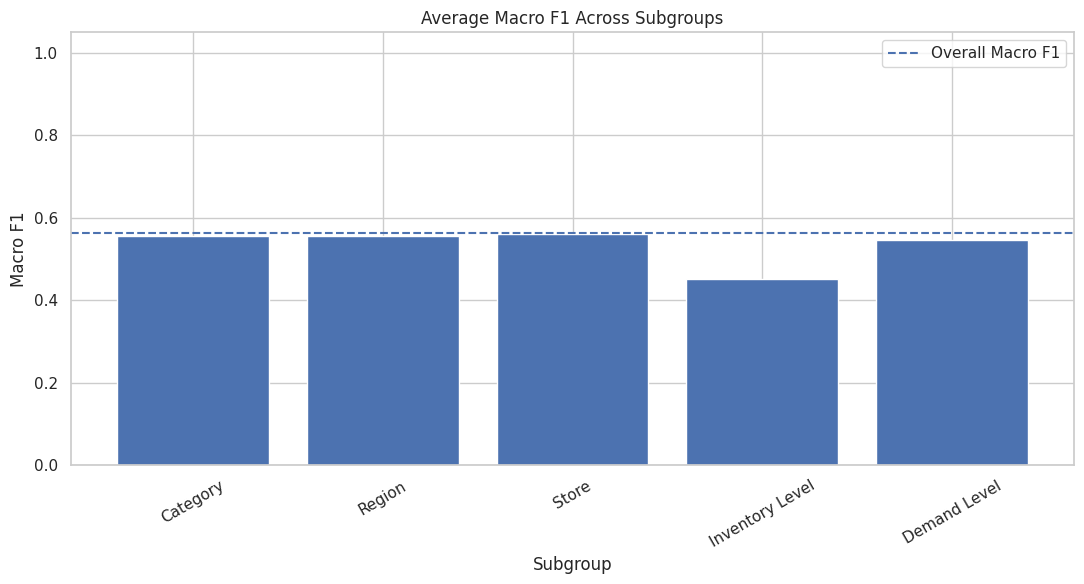


LOWER-PERFORMING SUBGROUPS

Category: No subgroup was more than 0.05 Macro F1 below overall performance.

Region: No subgroup was more than 0.05 Macro F1 below overall performance.

Store: No subgroup was more than 0.05 Macro F1 below overall performance.

Inventory Level:


,Inventory Group,Records,Accuracy,Macro F1,Weighted F1
0,High Inventory,5008,0.5687,0.5023,0.5912
1,Medium Inventory,5032,0.8994,0.4976,0.8981
2,Low Inventory,5020,0.9833,0.3570,0.9780



Demand Level: No subgroup was more than 0.05 Macro F1 below overall performance.

RISK-CLASS ROBUSTNESS


,precision,recall,f1-score,support
Low,0.9592,0.8737,0.9144,12660.0
Medium,0.3582,0.6108,0.4516,1683.0
High,0.3359,0.3082,0.3215,717.0



High-risk recall: 0.3082

High-risk recall represents the proportion of actually High-Risk records that the model successfully identifies.

ROBUSTNESS CONCLUSION

The model was evaluated across available business subgroups including category, region, store, inventory level, demand level and promotion status where those columns were available.

Subgroup performance should be interpreted alongside subgroup sample size. Lower performance in a small subgroup may be less reliable.

Risk-class recall was also examined to determine how effectively the model identifies each risk level.

BLOCK 14 COMPLETED SUCCESSFULLY

✓ Category robustness evaluated
✓ Regional robustness evaluated
✓ Store-level robustness evaluated
✓ Inventory sensitivity evaluated
✓ Demand sensitivity evaluated
⚠ Promotion robustness skipped (column unavailable)
✓ Risk-class performance tested
✓ Robustness results exported

The experimental evaluation is now complete.


In [26]:
# ==========================================================
# Inventory Management
# BLOCK 14 - ROBUSTNESS & SUBGROUP TESTING
# ==========================================================

print("=" * 70)
print("BLOCK 14 - ROBUSTNESS & SUBGROUP TESTING")
print("=" * 70)

# ----------------------------------------------------------
# 1. Prepare Evaluation Dataset
# ----------------------------------------------------------

robustness_df = prediction_analysis.copy()

print(f"\nEvaluation records: {len(robustness_df):,}")

# ----------------------------------------------------------
# 2. Overall Performance
# ----------------------------------------------------------

overall_accuracy = accuracy_score(
    robustness_df["Actual Risk"],
    robustness_df["Predicted Risk"]
)

overall_macro_f1 = f1_score(
    robustness_df["Actual Risk"],
    robustness_df["Predicted Risk"],
    average="macro",
    zero_division=0
)

overall_weighted_f1 = f1_score(
    robustness_df["Actual Risk"],
    robustness_df["Predicted Risk"],
    average="weighted",
    zero_division=0
)

print("\n" + "=" * 70)
print("OVERALL TEST PERFORMANCE")
print("=" * 70)

print(f"\nAccuracy    : {overall_accuracy:.4f}")
print(f"Macro F1    : {overall_macro_f1:.4f}")
print(f"Weighted F1 : {overall_weighted_f1:.4f}")

# ----------------------------------------------------------
# 3. Helper Function for Subgroup Evaluation
# ----------------------------------------------------------

def evaluate_subgroup(dataframe, group_column, minimum_records=20):

    if group_column not in dataframe.columns:
        print(f"Skipping {group_column}: column not found.")
        return pd.DataFrame(
            columns=[
                group_column,
                "Records",
                "Accuracy",
                "Macro F1",
                "Weighted F1"
            ]
        )

    results = []

    for group_value, group_data in dataframe.groupby(group_column):

        if len(group_data) < minimum_records:
            continue

        actual = group_data["Actual Risk"]
        predicted = group_data["Predicted Risk"]

        results.append({
            group_column: group_value,
            "Records": len(group_data),
            "Accuracy": accuracy_score(actual, predicted),
            "Macro F1": f1_score(
                actual, predicted,
                average="macro",
                zero_division=0
            ),
            "Weighted F1": f1_score(
                actual, predicted,
                average="weighted",
                zero_division=0
            )
        })

    result_df = pd.DataFrame(results)

    if not result_df.empty:
        result_df = result_df.sort_values(
            "Macro F1",
            ascending=False
        ).reset_index(drop=True)

    return result_df

# ----------------------------------------------------------
# 4. Category-Level Robustness
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("ROBUSTNESS BY CATEGORY")
print("=" * 70)

category_robustness = evaluate_subgroup(
    robustness_df, "Category"
)

display(category_robustness.round(4))

# ----------------------------------------------------------
# 5. Region-Level Robustness
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("ROBUSTNESS BY REGION")
print("=" * 70)

region_robustness = evaluate_subgroup(
    robustness_df, "Region"
)

display(region_robustness.round(4))

# ----------------------------------------------------------
# 6. Store-Level Robustness
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("ROBUSTNESS BY STORE")
print("=" * 70)

store_robustness = evaluate_subgroup(
    robustness_df,
    "Store ID",
    minimum_records=20
)

display(store_robustness.head(20).round(4))

# ----------------------------------------------------------
# 7. Inventory-Level Sensitivity
# ----------------------------------------------------------

if "Inventory Level" in robustness_df.columns:

    robustness_df["Inventory Group"] = pd.qcut(
        robustness_df["Inventory Level"],
        q=3,
        labels=["Low Inventory", "Medium Inventory", "High Inventory"],
        duplicates="drop"
    )

    print("\n" + "=" * 70)
    print("ROBUSTNESS BY INVENTORY LEVEL")
    print("=" * 70)

    inventory_robustness = evaluate_subgroup(
        robustness_df, "Inventory Group"
    )

    display(inventory_robustness.round(4))

else:
    inventory_robustness = pd.DataFrame()
    print("Inventory sensitivity skipped: column not found.")

# ----------------------------------------------------------
# 8. Demand-Level Sensitivity
# ----------------------------------------------------------

if "Demand" in robustness_df.columns:

    robustness_df["Demand Group"] = pd.qcut(
        robustness_df["Demand"],
        q=3,
        labels=["Low Demand", "Medium Demand", "High Demand"],
        duplicates="drop"
    )

    print("\n" + "=" * 70)
    print("ROBUSTNESS BY DEMAND LEVEL")
    print("=" * 70)

    demand_robustness = evaluate_subgroup(
        robustness_df, "Demand Group"
    )

    display(demand_robustness.round(4))

else:
    demand_robustness = pd.DataFrame()
    print("Demand sensitivity skipped: column not found.")

# ----------------------------------------------------------
# 9. Promotion-Level Robustness
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("ROBUSTNESS BY PROMOTION STATUS")
print("=" * 70)

if "Promotion" in robustness_df.columns:

    promotion_robustness = evaluate_subgroup(
        robustness_df, "Promotion"
    )

    display(promotion_robustness.round(4))

else:
    promotion_robustness = pd.DataFrame(
        columns=[
            "Promotion",
            "Records",
            "Accuracy",
            "Macro F1",
            "Weighted F1"
        ]
    )

    print(
        "Promotion robustness skipped: "
        "'Promotion' column is not available."
    )

# ----------------------------------------------------------
# 10. Compare Subgroup Performance
# ----------------------------------------------------------

subgroup_tables = {
    "Category": category_robustness,
    "Region": region_robustness,
    "Store": store_robustness,
    "Inventory Level": inventory_robustness,
    "Demand Level": demand_robustness,
    "Promotion": promotion_robustness
}

subgroup_summary = []

for subgroup_name, subgroup_table in subgroup_tables.items():

    if subgroup_table.empty:
        continue

    subgroup_summary.append({
        "Subgroup": subgroup_name,
        "Number of Groups": len(subgroup_table),
        "Average Accuracy": subgroup_table["Accuracy"].mean(),
        "Average Macro F1": subgroup_table["Macro F1"].mean(),
        "Minimum Macro F1": subgroup_table["Macro F1"].min(),
        "Maximum Macro F1": subgroup_table["Macro F1"].max()
    })

subgroup_summary_df = pd.DataFrame(subgroup_summary)

print("\n" + "=" * 70)
print("SUBGROUP ROBUSTNESS SUMMARY")
print("=" * 70)

display(subgroup_summary_df.round(4))

# ----------------------------------------------------------
# 11. Visualize Robustness
# ----------------------------------------------------------

if not subgroup_summary_df.empty:

    plt.figure(figsize=(11, 6))

    plt.bar(
        subgroup_summary_df["Subgroup"],
        subgroup_summary_df["Average Macro F1"]
    )

    plt.axhline(
        overall_macro_f1,
        linestyle="--",
        label="Overall Macro F1"
    )

    plt.title("Average Macro F1 Across Subgroups")
    plt.xlabel("Subgroup")
    plt.ylabel("Macro F1")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=30)
    plt.legend()
    plt.tight_layout()
    plt.show()

# ----------------------------------------------------------
# 12. Identify Lower-Performing Subgroups
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("LOWER-PERFORMING SUBGROUPS")
print("=" * 70)

for subgroup_name, subgroup_table in subgroup_tables.items():

    if subgroup_table.empty:
        continue

    threshold = overall_macro_f1 - 0.05

    lower_performing = subgroup_table[
        subgroup_table["Macro F1"] < threshold
    ]

    if not lower_performing.empty:

        print(f"\n{subgroup_name}:")
        display(lower_performing.round(4))

    else:
        print(
            f"\n{subgroup_name}: No subgroup was more than "
            "0.05 Macro F1 below overall performance."
        )

# ----------------------------------------------------------
# 13. Risk-Class Robustness
# ----------------------------------------------------------

risk_class_report = classification_report(
    robustness_df["Actual Risk"],
    robustness_df["Predicted Risk"],
    labels=["Low", "Medium", "High"],
    output_dict=True,
    zero_division=0
)

risk_class_robustness = pd.DataFrame(
    risk_class_report
).transpose()

risk_class_robustness = risk_class_robustness.loc[
    ["Low", "Medium", "High"],
    ["precision", "recall", "f1-score", "support"]
]

print("\n" + "=" * 70)
print("RISK-CLASS ROBUSTNESS")
print("=" * 70)

display(risk_class_robustness.round(4))

# ----------------------------------------------------------
# 14. High-Risk Recall
# ----------------------------------------------------------

high_risk_recall = risk_class_robustness.loc[
    "High", "recall"
]

print(f"\nHigh-risk recall: {high_risk_recall:.4f}")

print(
    "\nHigh-risk recall represents the proportion of actually "
    "High-Risk records that the model successfully identifies."
)

# ----------------------------------------------------------
# 15. Save Robustness Results
# ----------------------------------------------------------

category_robustness.to_csv(
    "inventory_management_robustness_category.csv",
    index=False
)

region_robustness.to_csv(
    "inventory_management_robustness_region.csv",
    index=False
)

store_robustness.to_csv(
    "inventory_management_robustness_store.csv",
    index=False
)

inventory_robustness.to_csv(
    "inventory_management_robustness_inventory.csv",
    index=False
)

demand_robustness.to_csv(
    "inventory_management_robustness_demand.csv",
    index=False
)

promotion_robustness.to_csv(
    "inventory_management_robustness_promotion.csv",
    index=False
)

subgroup_summary_df.to_csv(
    "inventory_management_subgroup_summary.csv",
    index=False
)

risk_class_robustness.to_csv(
    "inventory_management_risk_class_robustness.csv"
)

# ----------------------------------------------------------
# 16. Final Robustness Conclusion
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("ROBUSTNESS CONCLUSION")
print("=" * 70)

print(
    "\nThe model was evaluated across available business subgroups "
    "including category, region, store, inventory level, demand level "
    "and promotion status where those columns were available."
)

print(
    "\nSubgroup performance should be interpreted alongside subgroup "
    "sample size. Lower performance in a small subgroup may be less reliable."
)

print(
    "\nRisk-class recall was also examined to determine how effectively "
    "the model identifies each risk level."
)

print("\n" + "=" * 70)
print("BLOCK 14 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\n✓ Category robustness evaluated")
print("✓ Regional robustness evaluated")
print("✓ Store-level robustness evaluated")
print("✓ Inventory sensitivity evaluated")
print("✓ Demand sensitivity evaluated")

if "Promotion" in robustness_df.columns:
    print("✓ Promotion robustness tested")
else:
    print("⚠ Promotion robustness skipped (column unavailable)")

print("✓ Risk-class performance tested")
print("✓ Robustness results exported")

print("\nThe experimental evaluation is now complete.")